# Proteomic Profiling of *S. cerevisiae* Perturbed in RNA Polymerase III
## Master's Thesis: Complete Minimalist & Pre-calculated Plot Generator
**Author:** Ignacy Makowski  
**Affiliation:** Faculty of Mathematics, Informatics and Mechanics, University of Warsaw  

---
### Notebook Structure & Visual Standards
This notebook contains the complete, self-contained, and pre-calculated visualization suite reproducing **every figure** included in the Master's thesis:
1. **Section 1: Polish SWATH-MS Dataset Quality Control & Exploration** (Figures 4.1 & 4.2)
   - Figure 4.2: Coefficient of Variation (CV) distributions across conditions
   - Figure 4.1 (Bottom): Principal Component Analysis (PCA) by condition and strain
   - Figure 4.1 (Top): Hierarchical clustering heatmap of proteome profiles
2. **Section 2: Empirical Bayes Differential Abundance Analysis (*limma*)** (Figure 4.3)
   - Figure 4.3: Multi-panel Volcano plots for all 5 mutant vs WT comparisons
3. **Section 3: Codon Usage Bias & Translation Homeostasis** (Figures 4.4 & 4.5)
   - Figure 4.4: Scatter plots of expression logFC vs target codon frequency (`AAA`, `CAA`, `GAA`, `AAG`)
   - Figure 4.5: Categorical heatmap of gene count distributions
4. **Section 4: Functional Discovery: KEGG Metabolic Pathway Enrichment** (Figures 4.6 – 4.10)
   - Top enriched pathways across carbon sources and growth temperatures
5. **Section 5: Multi-Dataset Harmonization & ComBat Batch Correction** (Figures 4.21, 4.22, 4.23)
   - Figure 4.21: Evaluation of ComBat correction (PCA and Intensity Boxplots Before/After)
   - Figure 4.22: Heatmap of the harmonized proteome (1,589 common proteins)
   - Figure 4.23: UMAP projection across all strains, carbon sources, and phases
6. **Section 6: Cellular Stress Response & Translation Machinery** (Figures 4.17 – 4.19)
   - Heatmaps of molecular chaperones and tRNA-associated proteins

*Color Palette:* Every plot adheres strictly to the **Okabe-Ito color-blind friendly palette** with verified, large typography ($\ge 12-14\text{ pt}$).


In [1]:
# Cell 1: Setup & Okabe-Ito Color Palette
import os
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from scipy.stats import pearsonr

# Set clean typography defaults for publication figures
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'font.size': 12,
    'axes.labelsize': 13,
    'axes.titlesize': 14,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 15,
    'figure.autolayout': True
})

# Verified color-blind accessible Okabe-Ito palette (Yellow removed per supervisor feedback)
OKABE_ITO = {
    'black': '#000000',
    'orange': '#E69F00',
    'sky_blue': '#56B4E9',
    'bluish_green': '#009E73',
    'blue': '#0072B2',
    'vermilion': '#D55E00',
    'reddish_purple': '#CC79A7',
    'grey': '#999999'
}

print("Environment initialized. Okabe-Ito palette configured.")

os.makedirs('output_figures', exist_ok=True)
print('Output directory output_figures/ ready.')


Environment initialized. Okabe-Ito palette configured.


---
### Section 1: Quality Control and Exploratory Profiling of SWATH-MS Dataset
Evaluating biological and technical replicate reproducibility via Coefficient of Variation (CV) distributions (Figure 4.2), and mapping global proteomic variation using unsupervised Principal Component Analysis (PCA) and hierarchical clustering (Figure 4.1).


Median CV: 18.52%. Explained Variance: PC1=48.7%, PC2=16.1%.


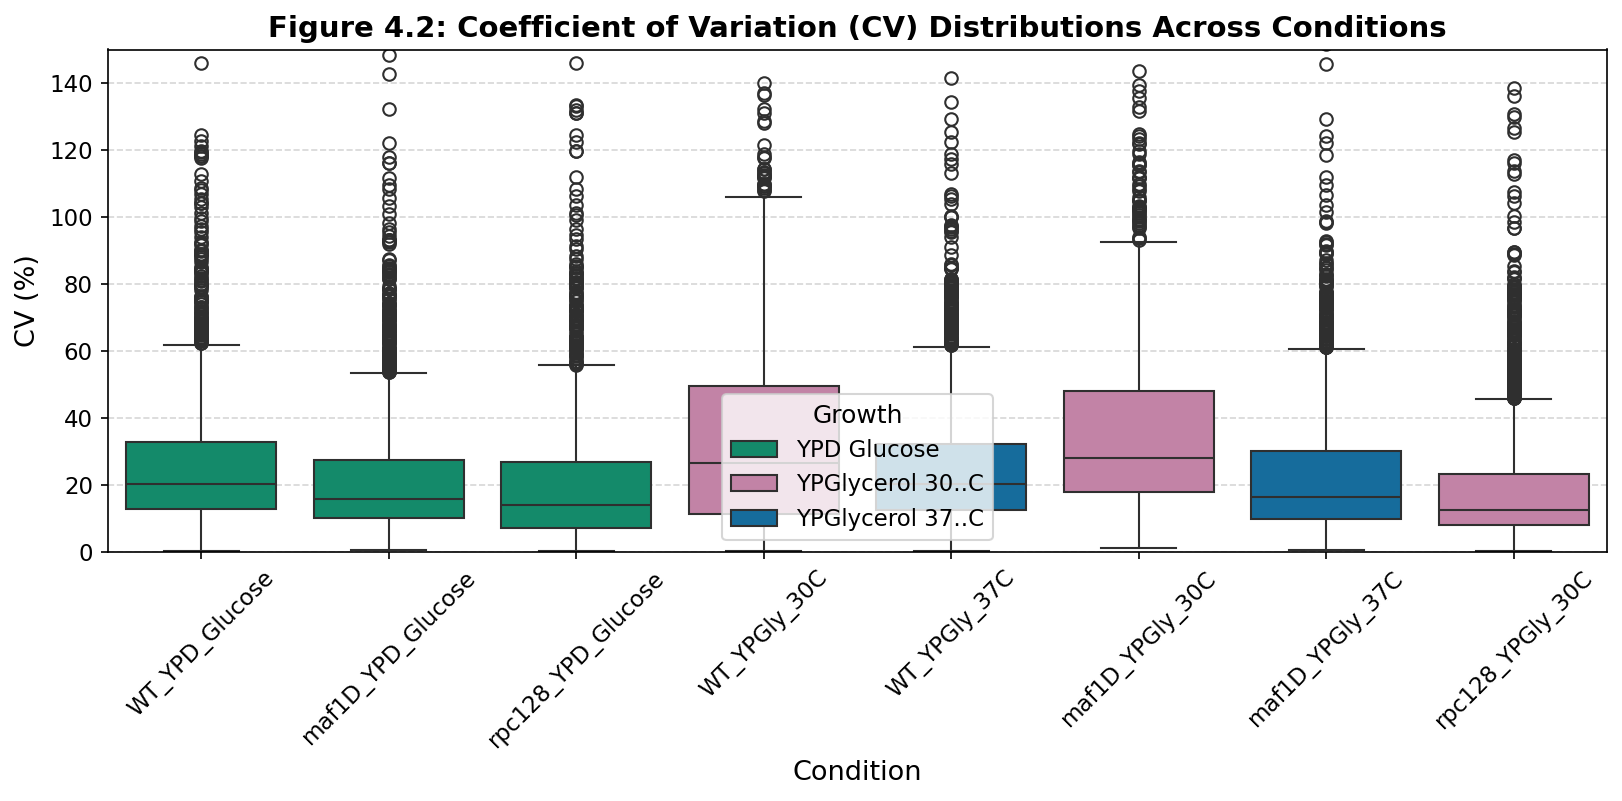

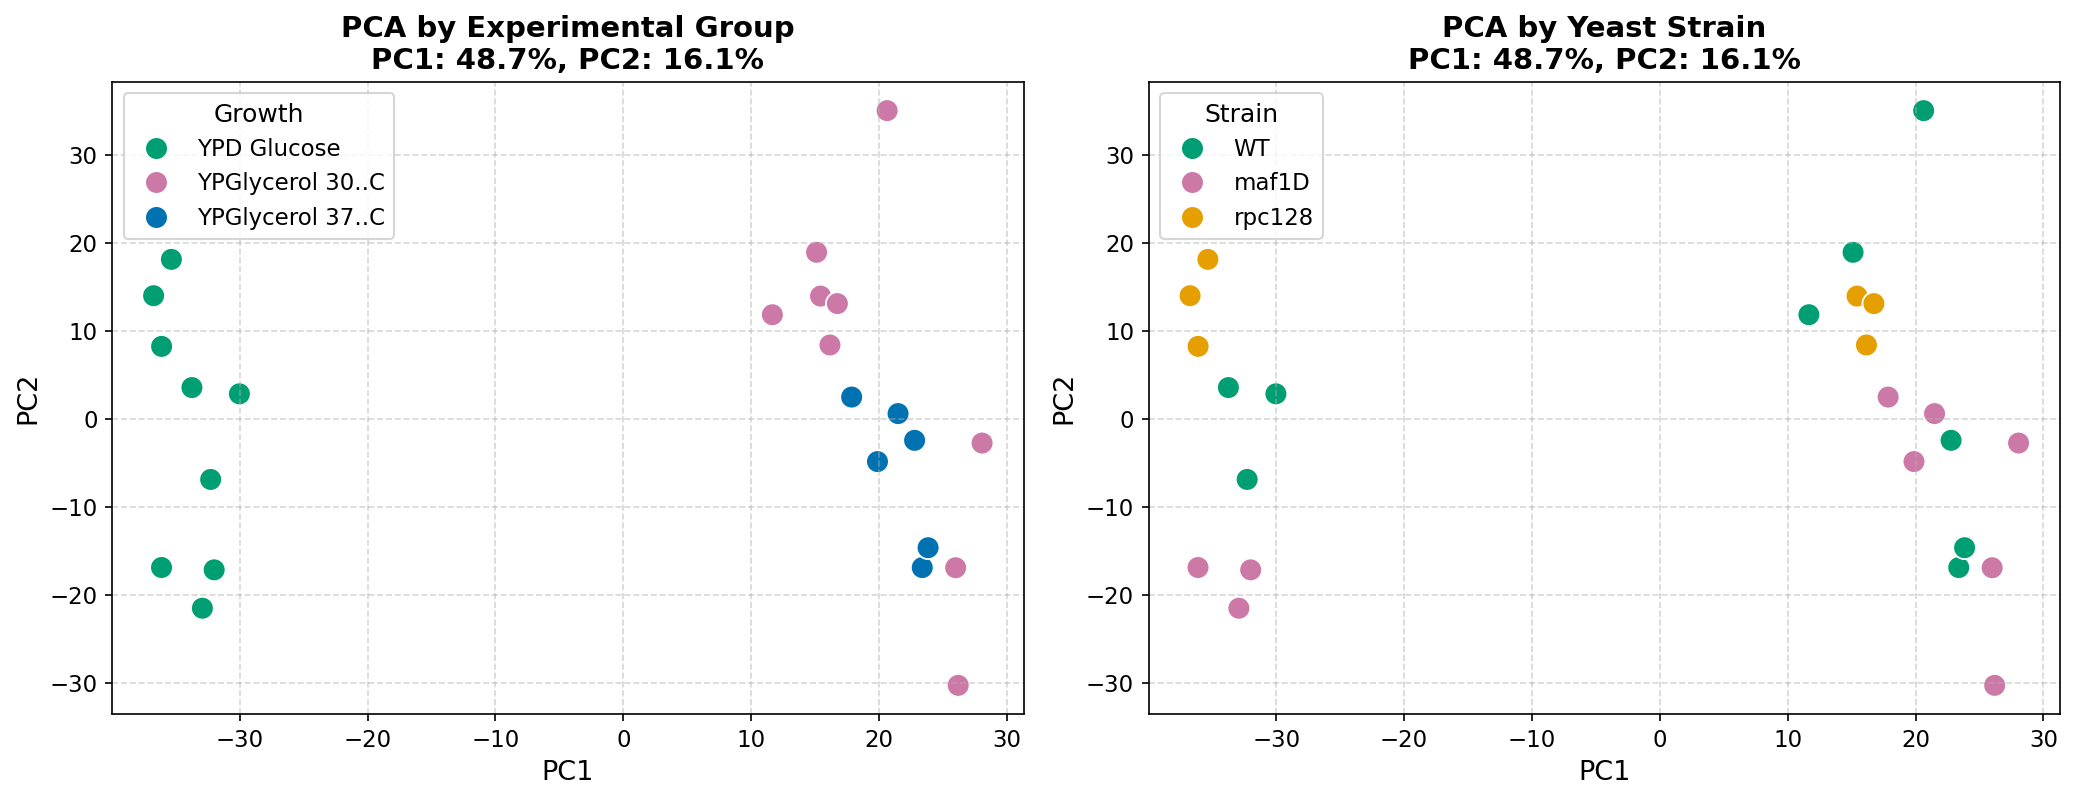

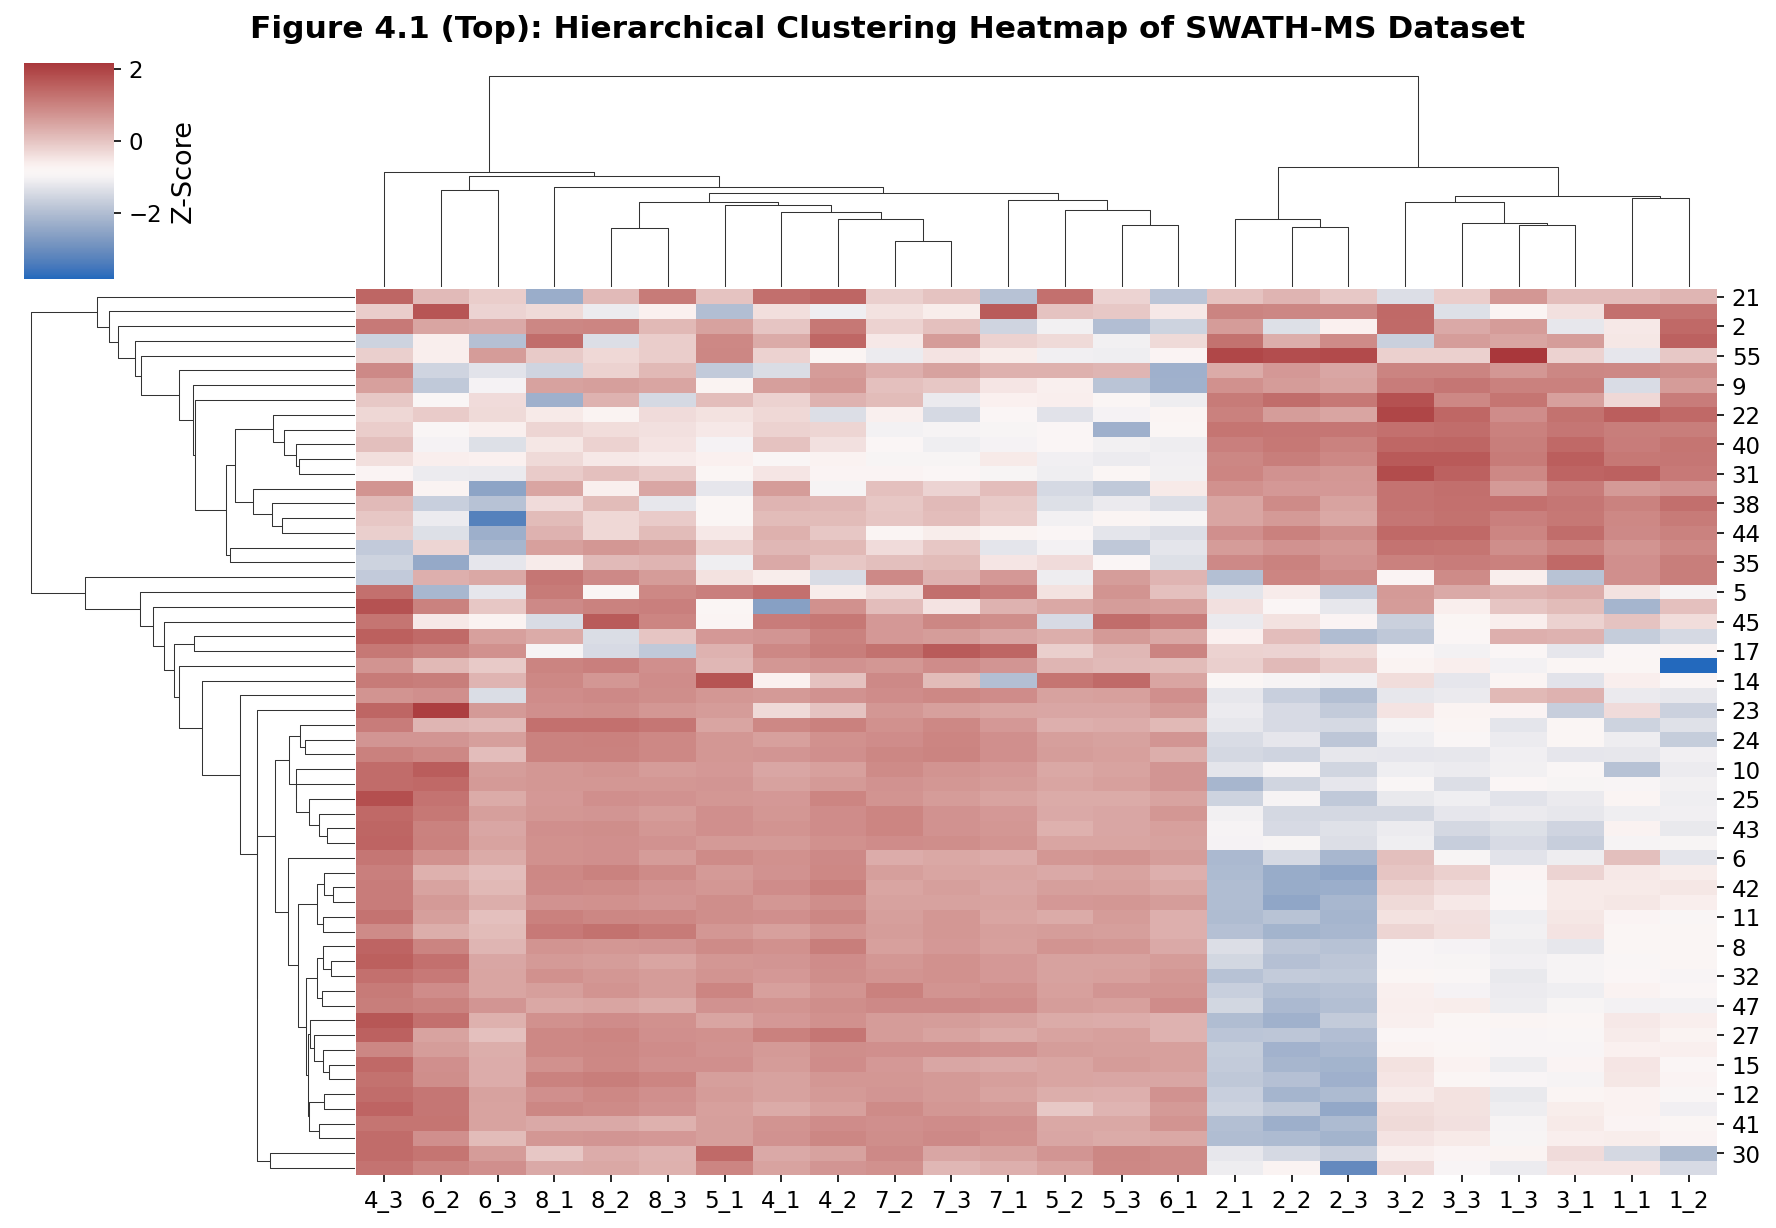

In [2]:
# Cell 2: Figure 4.1 & 4.2 - CV Boxplot, PCA, and Clustered Heatmap
data_path = 'data/swathms_mutants.csv'
if os.path.exists(data_path):
    poland_raw = pd.read_csv(data_path)
    
    cond_cols = {
        'WT_YPD_Glucose': ['1_1 ', '1_2 ', '1_3 '],
        'maf1D_YPD_Glucose': ['2_1 ', '2_2 ', '2_3 '],
        'rpc128_YPD_Glucose': ['3_1 ', '3_2 ', '3_3 '],
        'WT_YPGly_30C': ['4_1 ', '4_2 ', '4_3 '],
        'WT_YPGly_37C': ['5_1 ', '5_2 ', '5_3 '],
        'maf1D_YPGly_30C': ['6_1 ', '6_2 ', '6_3 '],
        'maf1D_YPGly_37C': ['7_1 ', '7_2 ', '7_3 '],
        'rpc128_YPGly_30C': ['8_1 ', '8_2 ', '8_3 ']
    }
    
    # 1. Figure 4.2: CV Boxplot
    cv_records = []
    for cond_name, cols in cond_cols.items():
        sub = poland_raw[cols].copy()
        mean_val = sub.mean(axis=1)
        std_val = sub.std(axis=1)
        cv = (std_val / mean_val) * 100
        cv = cv[np.isfinite(cv) & (mean_val > 0)]
        for val in cv:
            growth = 'YPD Glucose' if 'YPD' in cond_name else ('YPGlycerol 30..C' if '30C' in cond_name else 'YPGlycerol 37..C')
            cv_records.append({'Condition': cond_name, 'CV': val, 'Growth': growth})
    
    df_cv = pd.DataFrame(cv_records)
    
    fig_cv, ax_cv = plt.subplots(figsize=(11, 5.5))
    palette_growth = {
        'YPD Glucose': OKABE_ITO['bluish_green'],
        'YPGlycerol 30..C': OKABE_ITO['reddish_purple'],
        'YPGlycerol 37..C': OKABE_ITO['blue']
    }
    sns.boxplot(data=df_cv, x='Condition', y='CV', hue='Growth', palette=palette_growth, ax=ax_cv)
    ax_cv.set_title('Figure 4.2: Coefficient of Variation (CV) Distributions Across Conditions', fontweight='bold')
    ax_cv.set_ylabel('CV (%)')
    ax_cv.set_ylim(0, 150)
    ax_cv.tick_params(axis='x', rotation=45)
    ax_cv.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    fig_cv.savefig('output_figures/Figure_4_2_poland_grouped_cv_boxplot.pdf', bbox_inches='tight')
    plt.show()
    
    # 2. Figure 4.1 Bottom: PCA Dual Panels
    all_cols = [c for cols in cond_cols.values() for c in cols]
    mat = np.log2(poland_raw[all_cols].dropna().values + 1).T
    
    # Pure SVD PCA computation
    mean = np.mean(mat, axis=0)
    centered = mat - mean
    U, S, Vt = np.linalg.svd(centered, full_matrices=False)
    coords = U[:, :2] * S[:2]
    var_exp = (S**2) / np.sum(S**2)
    
    df_pca = pd.DataFrame(coords, columns=['PC1', 'PC2'])
    df_pca['Sample'] = all_cols
    df_pca['Condition'] = [k for k, cols in cond_cols.items() for c in cols]
    df_pca['Strain'] = df_pca['Condition'].apply(lambda x: 'WT' if 'WT' in x else ('maf1D' if 'maf1D' in x else 'rpc128'))
    df_pca['Growth'] = df_pca['Condition'].apply(lambda x: 'YPD Glucose' if 'YPD' in x else ('YPGlycerol 30..C' if '30C' in x else 'YPGlycerol 37..C'))
    
    fig_pca, (ax_p1, ax_p2) = plt.subplots(1, 2, figsize=(14, 5.5))
    sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='Growth', palette=palette_growth, s=120, ax=ax_p1)
    ax_p1.set_title(f'PCA by Experimental Group\nPC1: {var_exp[0]*100:.1f}%, PC2: {var_exp[1]*100:.1f}%', fontweight='bold')
    ax_p1.grid(True, linestyle='--', alpha=0.5)
    
    palette_strain = {'WT': OKABE_ITO['bluish_green'], 'maf1D': OKABE_ITO['reddish_purple'], 'rpc128': OKABE_ITO['orange']}
    sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='Strain', palette=palette_strain, s=120, ax=ax_p2)
    ax_p2.set_title(f'PCA by Yeast Strain\nPC1: {var_exp[0]*100:.1f}%, PC2: {var_exp[1]*100:.1f}%', fontweight='bold')
    ax_p2.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    fig_pca.savefig('output_figures/Figure_4_1_PCA_polish_data.pdf', bbox_inches='tight')
    plt.show()
    
    # 3. Figure 4.1 Top: Hierarchical Clustering Heatmap
    clean_mat = np.log2(poland_raw[all_cols].dropna().values + 1)
    # Row-wise Z-score scaling
    z_mat = (clean_mat - clean_mat.mean(axis=1, keepdims=True)) / clean_mat.std(axis=1, keepdims=True)
    top_var_idx = np.argsort(clean_mat.var(axis=1))[-60:] # Top 60 most variable proteins
    
    df_heatmap = pd.DataFrame(z_mat[top_var_idx], columns=[c.strip() for c in all_cols])
    g_heat = sns.clustermap(df_heatmap, figsize=(12, 8), cmap='vlag', col_cluster=True, row_cluster=True,
                            cbar_kws={'label': 'Z-Score'})
    g_heat.fig.suptitle('Figure 4.1 (Top): Hierarchical Clustering Heatmap of SWATH-MS Dataset', fontweight='bold', y=1.02)
    g_heat.savefig('output_figures/Figure_4_1_heatmap_polish_data.pdf', bbox_inches='tight')
    plt.show()
    
else:
    print(f"Notice: '{data_path}' not found. Proteomic datasets are available from the author upon reasonable request.")


---
### Section 2: Differential Abundance Analysis via Empirical Bayes (*limma*)
Visualizing statistically significant alterations in protein abundance ($|\log_2\text{FC}| > 1$, $p_{\text{adj}} < 0.05$) across the 5 core biological contrasts. Significant proteins are highlighted in **Okabe-Ito Purple** (`#CC79A7`).


WT vs maf1Δ (YPGly 30°C): 415 significant proteins out of 1660
WT vs maf1Δ (YPD): 98 significant proteins out of 1660
WT vs rpc128-1007 (YPGly 30°C): 55 significant proteins out of 1660
WT vs rpc128-1007 (YPD): 20 significant proteins out of 1660
WT vs maf1Δ (YPGly 37°C): 19 significant proteins out of 1660


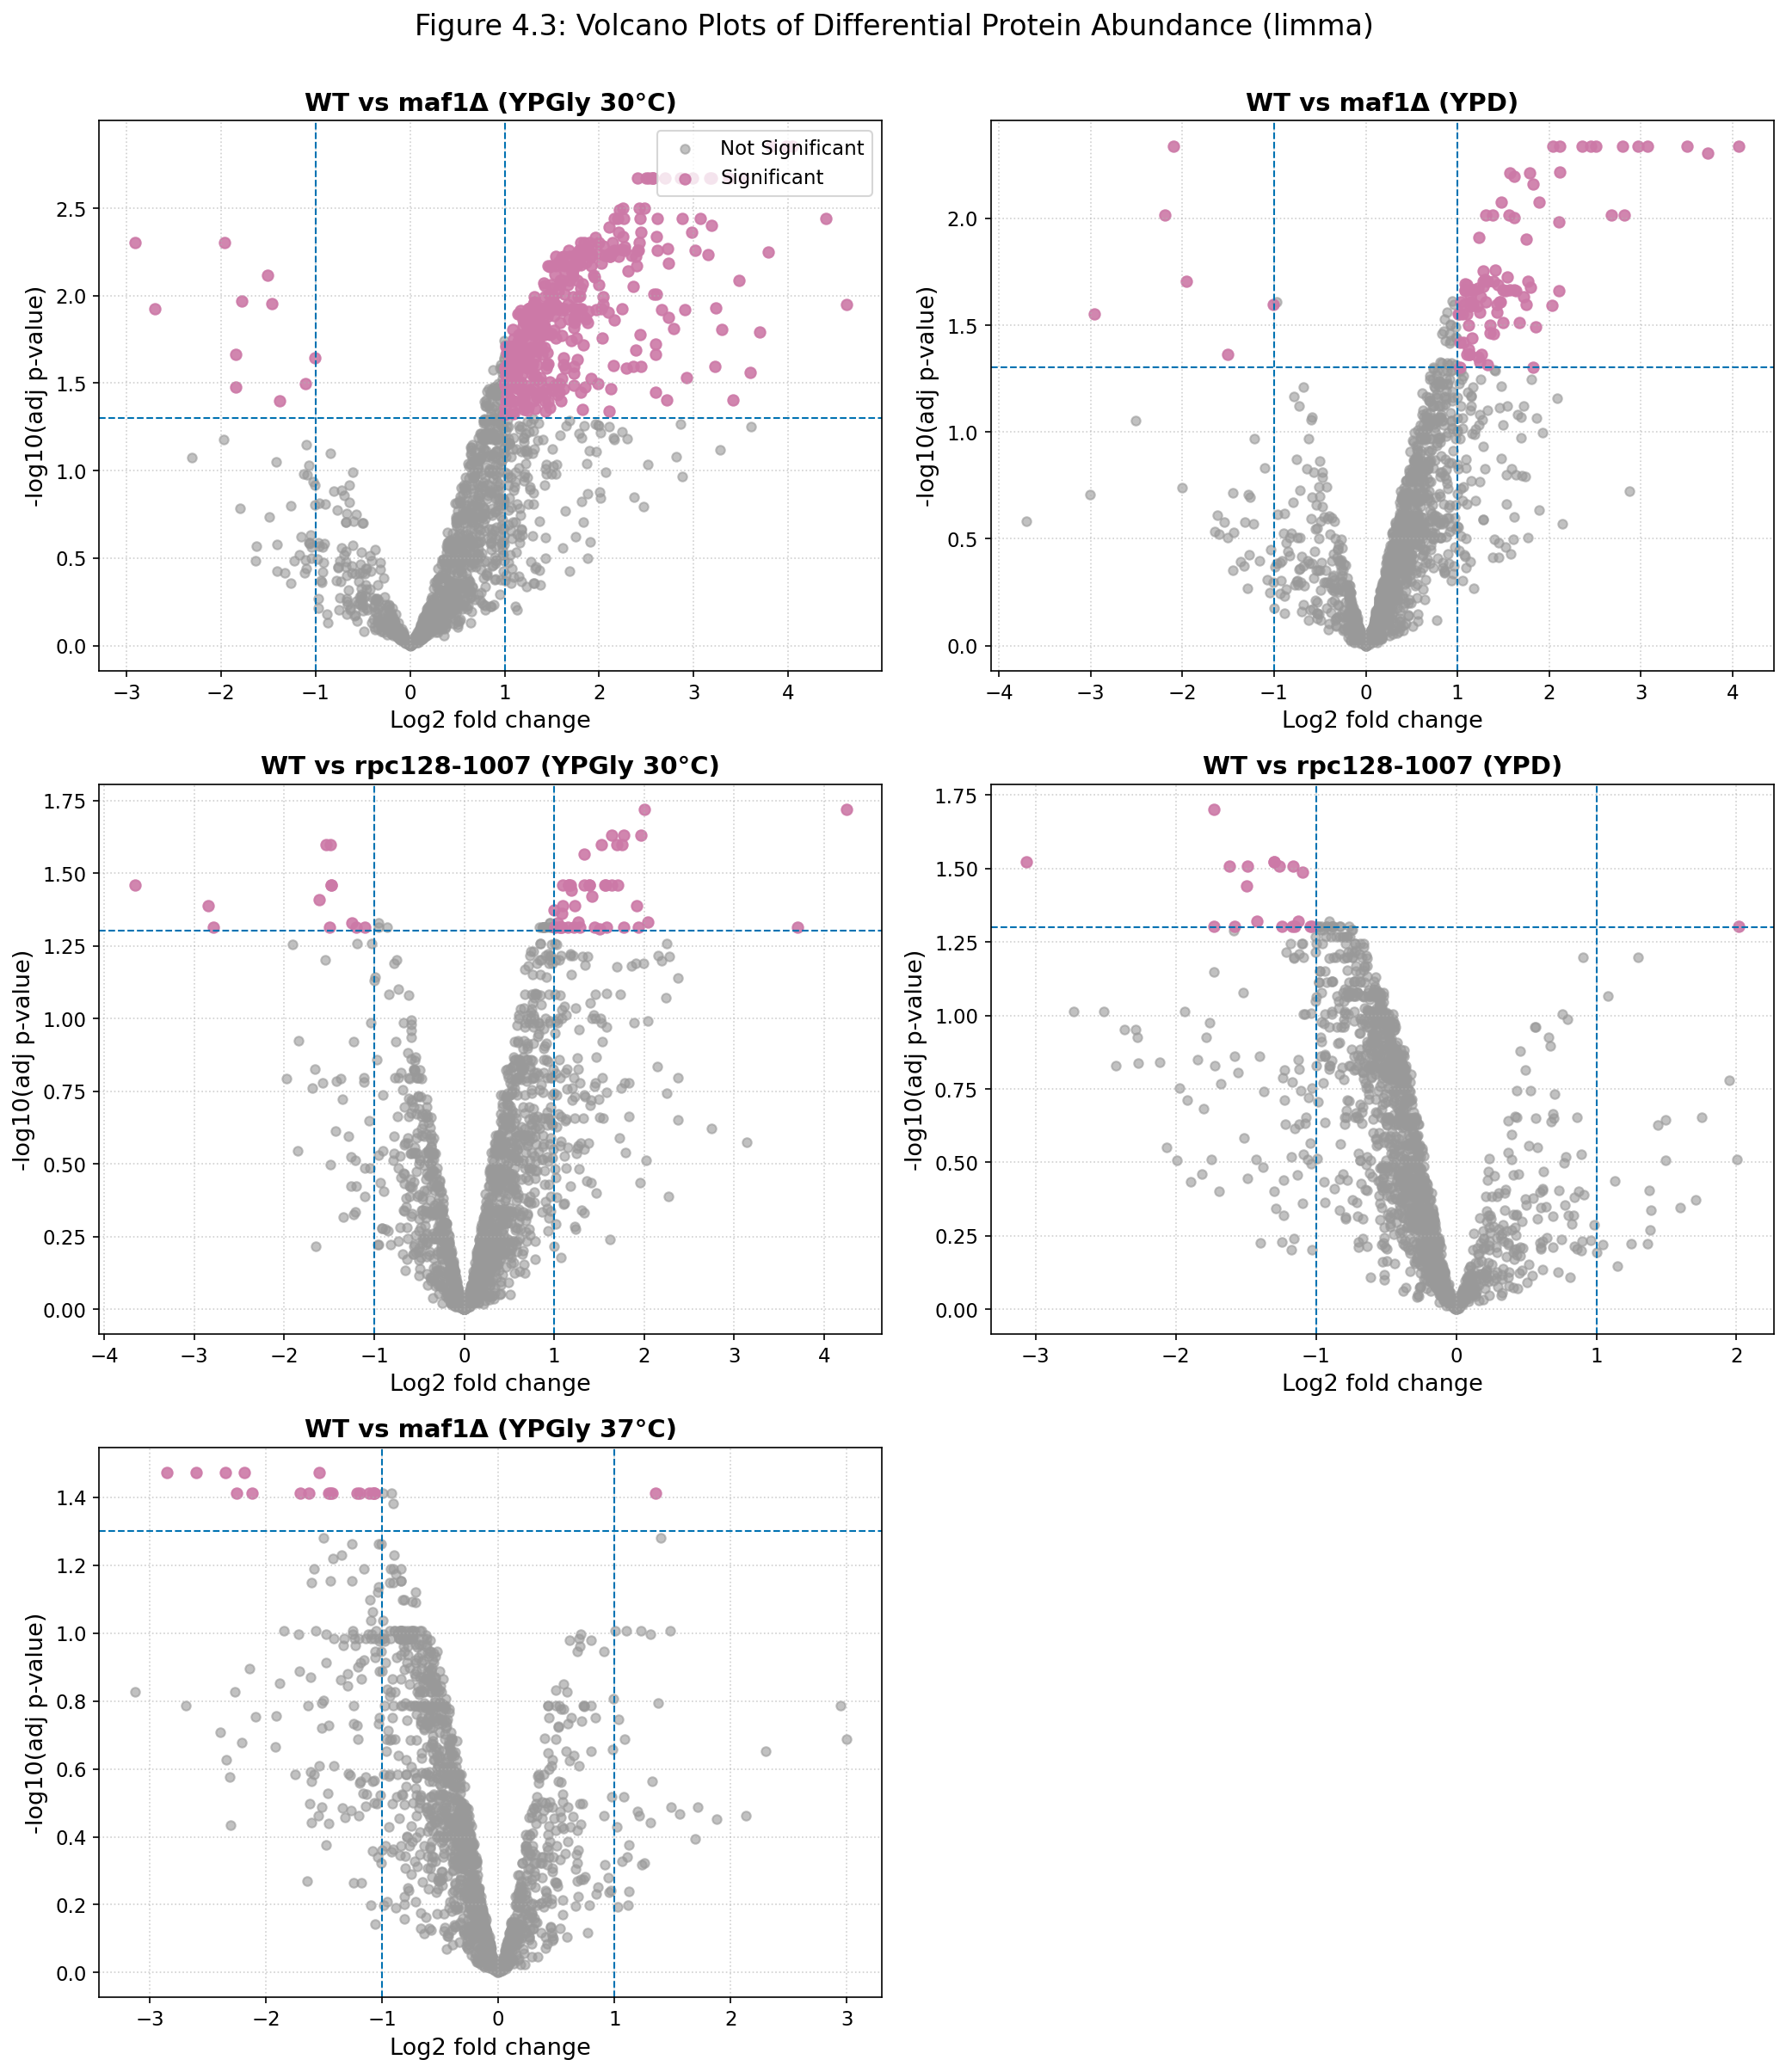

In [3]:
# Cell 3: Figure 4.3 - Combined 5-Panel Volcano Plots (limma)
comparisons = [
    ('results_WT_YPGly_30C_vs_maf1D_YPGly_30C.csv', 'WT vs maf1Δ (YPGly 30°C)'),
    ('results_WT_YPD_Glucose_vs_maf1D_YPD_Glucose.csv', 'WT vs maf1Δ (YPD)'),
    ('results_WT_YPGly_30C_vs_rpc128_YPGly_30C.csv', 'WT vs rpc128-1007 (YPGly 30°C)'),
    ('results_WT_YPD_Glucose_vs_rpc128_YPD_Glucose.csv', 'WT vs rpc128-1007 (YPD)'),
    ('results_WT_YPGly_37C_vs_maf1D_YPGly_37C.csv', 'WT vs maf1Δ (YPGly 37°C)')
]

fig_volc, axes = plt.subplots(3, 2, figsize=(14, 16))
axes_flat = axes.flatten()

for idx, (fname, title) in enumerate(comparisons):
    ax = axes_flat[idx]
    limma_dir = 'data/limma' if os.path.exists('data/limma') else 'mcbs_based/output_plots_combat/volcano_plots/limma'
    path = os.path.join(limma_dir, fname)
    if not os.path.exists(path):
        if idx == 0:
            print("Notice: Limma comparison files not found in 'data/limma/'. Datasets available upon request.")
        continue
    df = pd.read_csv(path)
    
    df['Significant'] = (df['adj.P.Val'] < 0.05) & (df['logFC'].abs() > 1.0)
    
    ax.scatter(df[~df['Significant']]['logFC'], -np.log10(df[~df['Significant']]['adj.P.Val']),
               color=OKABE_ITO['grey'], alpha=0.6, s=25, label='Not Significant')
    ax.scatter(df[df['Significant']]['logFC'], -np.log10(df[df['Significant']]['adj.P.Val']),
               color=OKABE_ITO['reddish_purple'], alpha=0.9, s=35, label='Significant')
    
    ax.axhline(-np.log10(0.05), color=OKABE_ITO['blue'], linestyle='--', linewidth=1)
    ax.axvline(1.0, color=OKABE_ITO['blue'], linestyle='--', linewidth=1)
    ax.axvline(-1.0, color=OKABE_ITO['blue'], linestyle='--', linewidth=1)
    
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Log2 fold change')
    ax.set_ylabel('-log10(adj p-value)')
    ax.grid(True, linestyle=':', alpha=0.6)
    if idx == 0:
        ax.legend(loc='upper right')

fig_volc.delaxes(axes_flat[5])
plt.suptitle('Figure 4.3: Volcano Plots of Differential Protein Abundance (limma)', fontsize=16, y=1.002)
plt.tight_layout()
fig_volc.savefig('output_figures/Figure_4_3_combined_volcano.pdf', bbox_inches='tight')
plt.show()


---
### Section 3: Codon Usage Bias & Translation Disconnect
Testing for direct translation elongation bottlenecks by correlating protein abundance shifts with target codon frequencies (`AAA`, `CAA`, `GAA`, `AAG`). The lack of significant correlation demonstrates that proteomic shifts reflect physiological pathway regulation rather than codon-specific stalls.


5vs7_ztest: r=0.0406, p=0.0989
1vs3_ztest: r=0.0365, p=0.1383
4vs8_ztest: r=0.0477, p=0.0524
4vs6_ztest: r=0.0246, p=0.3180
1vs2_ztest: r=0.0130, p=0.5969


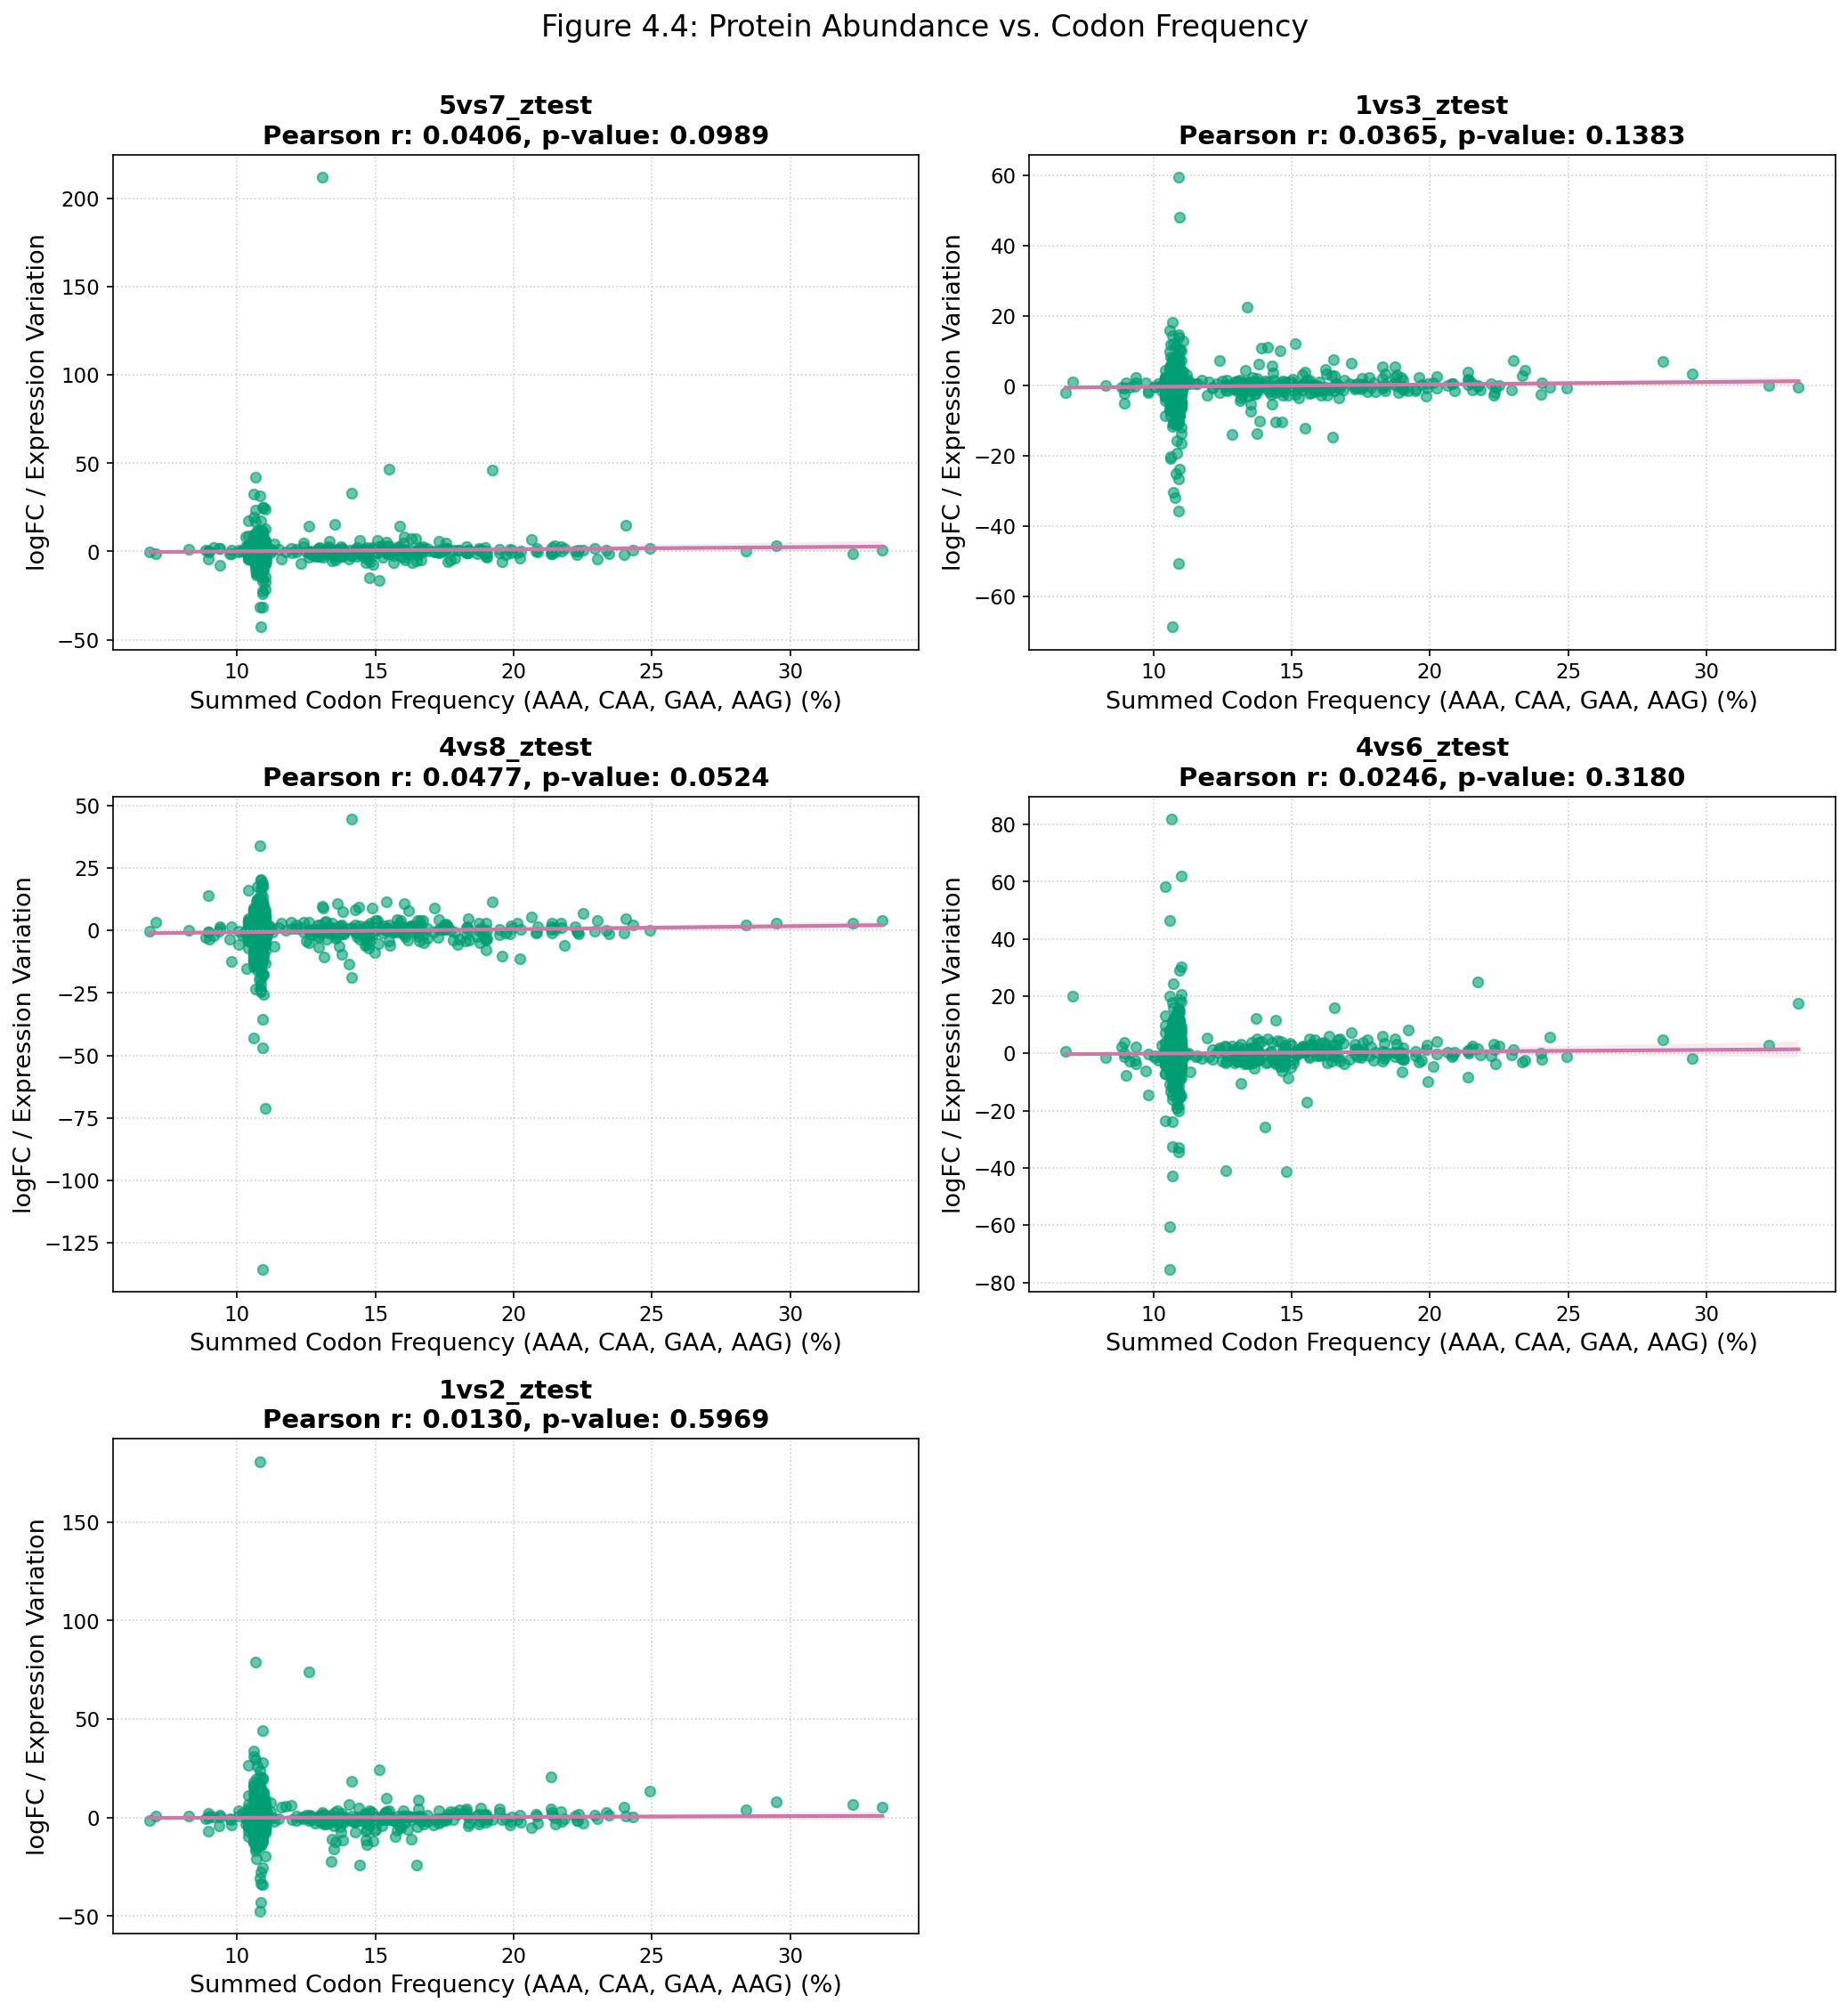

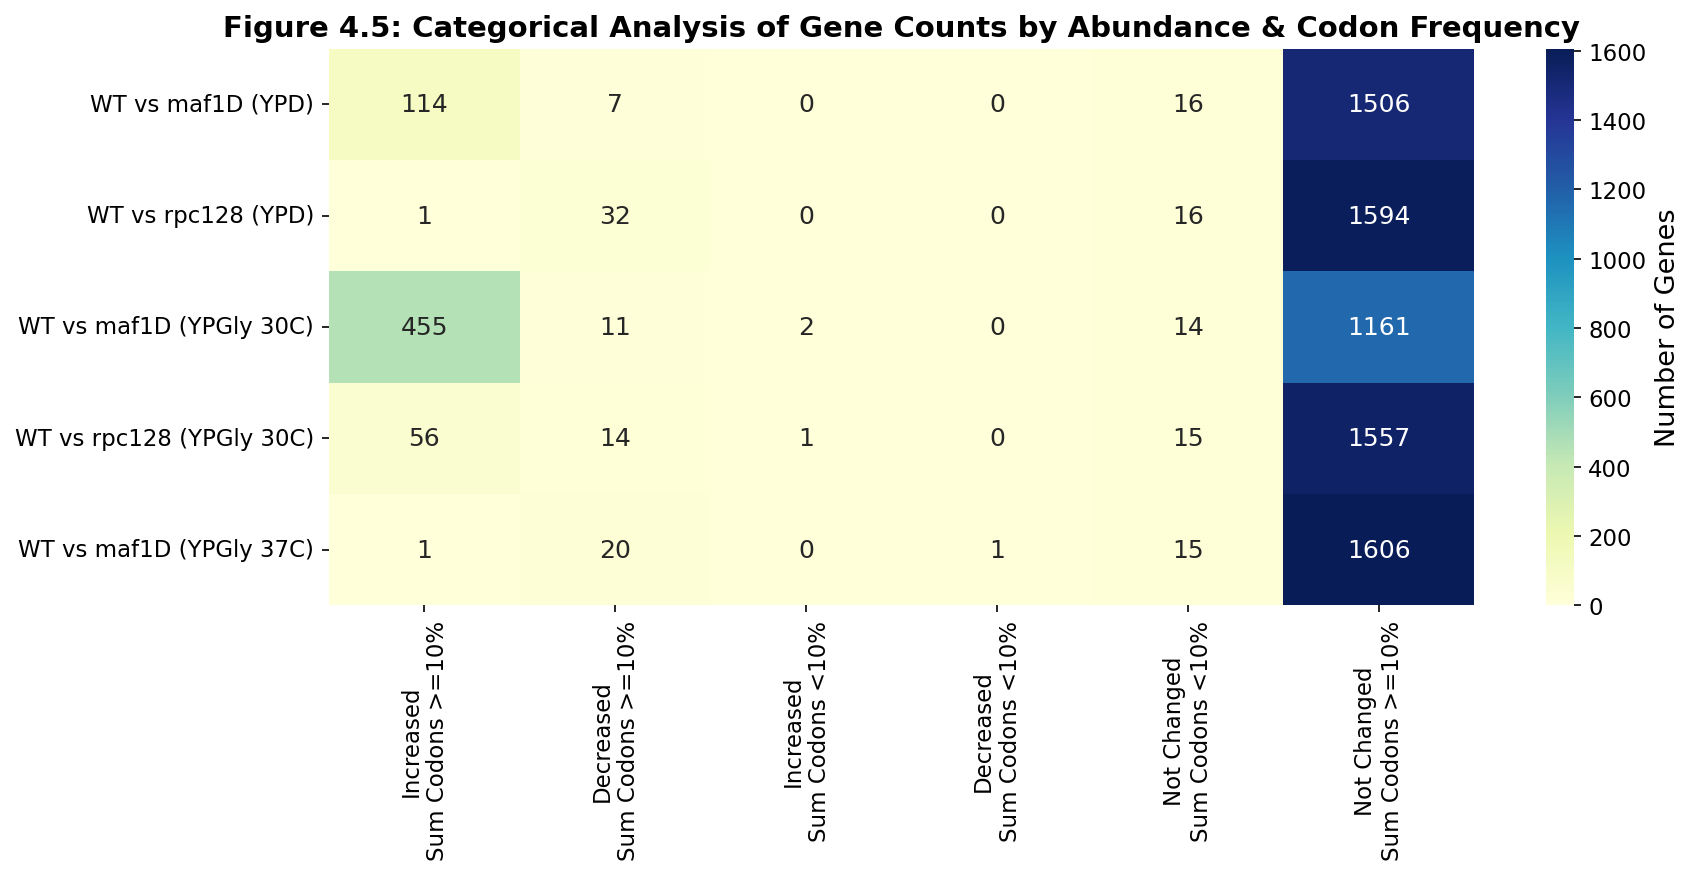

In [4]:
codon_path = 'data/final_merged_data.csv'
if os.path.exists(codon_path):
    df_codon = pd.read_csv(codon_path)
    
    comp_ids = df_codon['Dataset ID'].unique()
    fig_codon, axes_c = plt.subplots(3, 2, figsize=(14, 15))
    axes_c_flat = axes_c.flatten()
    
    for idx, comp in enumerate(comp_ids[:5]):
        ax = axes_c_flat[idx]
        sub = df_codon[df_codon['Dataset ID'] == comp].dropna(subset=['zscore', 'SummarizedCodonFrequencyPercentage'])
        x = sub['SummarizedCodonFrequencyPercentage']
        y = sub['zscore']
        
        r, p = pearsonr(x, y)
        
        sns.regplot(x=x, y=y, ax=ax,
                    scatter_kws={'alpha': 0.6, 'color': OKABE_ITO['bluish_green'], 's': 30},
                    line_kws={'color': OKABE_ITO['reddish_purple'], 'linewidth': 2})
        
        ax.set_title(f'{comp}\nPearson r: {r:.4f}, p-value: {p:.4f}', fontweight='bold')
        ax.set_xlabel('Summed Codon Frequency (AAA, CAA, GAA, AAG) (%)')
        ax.set_ylabel('logFC / Expression Variation')
        ax.grid(True, linestyle=':', alpha=0.6)
    
    fig_codon.delaxes(axes_c_flat[5])
    plt.suptitle('Figure 4.4: Protein Abundance vs. Codon Frequency', fontsize=16, y=1.002)
    plt.tight_layout()
    fig_codon.savefig('output_figures/Figure_4_4_combined_ztest_trend.pdf', bbox_inches='tight')
    plt.show()
    
    # Figure 4.5: Categorical Heatmap of Gene Counts
    cats_data = [
        [114, 7, 0, 0, 16, 1506],
        [1, 32, 0, 0, 16, 1594],
        [455, 11, 2, 0, 14, 1161],
        [56, 14, 1, 0, 15, 1557],
        [1, 20, 0, 1, 15, 1606]
    ]
    categories = [
        'Increased\nSum Codons >=10%', 'Decreased\nSum Codons >=10%',
        'Increased\nSum Codons <10%', 'Decreased\nSum Codons <10%',
        'Not Changed\nSum Codons <10%', 'Not Changed\nSum Codons >=10%'
    ]
    index_labels = [
        'WT vs maf1D (YPD)', 'WT vs rpc128 (YPD)',
        'WT vs maf1D (YPGly 30C)', 'WT vs rpc128 (YPGly 30C)',
        'WT vs maf1D (YPGly 37C)'
    ]
    df_heat = pd.DataFrame(cats_data, index=index_labels, columns=categories)
    
    fig_h, ax_h = plt.subplots(figsize=(12, 6))
    sns.heatmap(df_heat, annot=True, fmt='d', cmap='YlGnBu', cbar_kws={'label': 'Number of Genes'}, ax=ax_h)
    ax_h.set_title('Figure 4.5: Categorical Analysis of Gene Counts by Abundance & Codon Frequency', fontweight='bold')
    plt.tight_layout()
    fig_h.savefig('output_figures/Figure_4_5_combined_gene_counts.pdf', bbox_inches='tight')
    plt.show()
    
else:
    print(f"Notice: '{codon_path}' not found. Proteomic datasets are available from the author upon reasonable request.")


---
### Section 4: Functional Discovery: KEGG Pathway Enrichment Analysis
Bar plots of the top over-represented biological pathways (adjusted $p$-value $< 0.1$, overlap $> 10\%$) among up-regulated (Purple `#CC79A7`) and down-regulated (Green `#009E73`) proteins.


KEGG pathway enrichment plots generated.


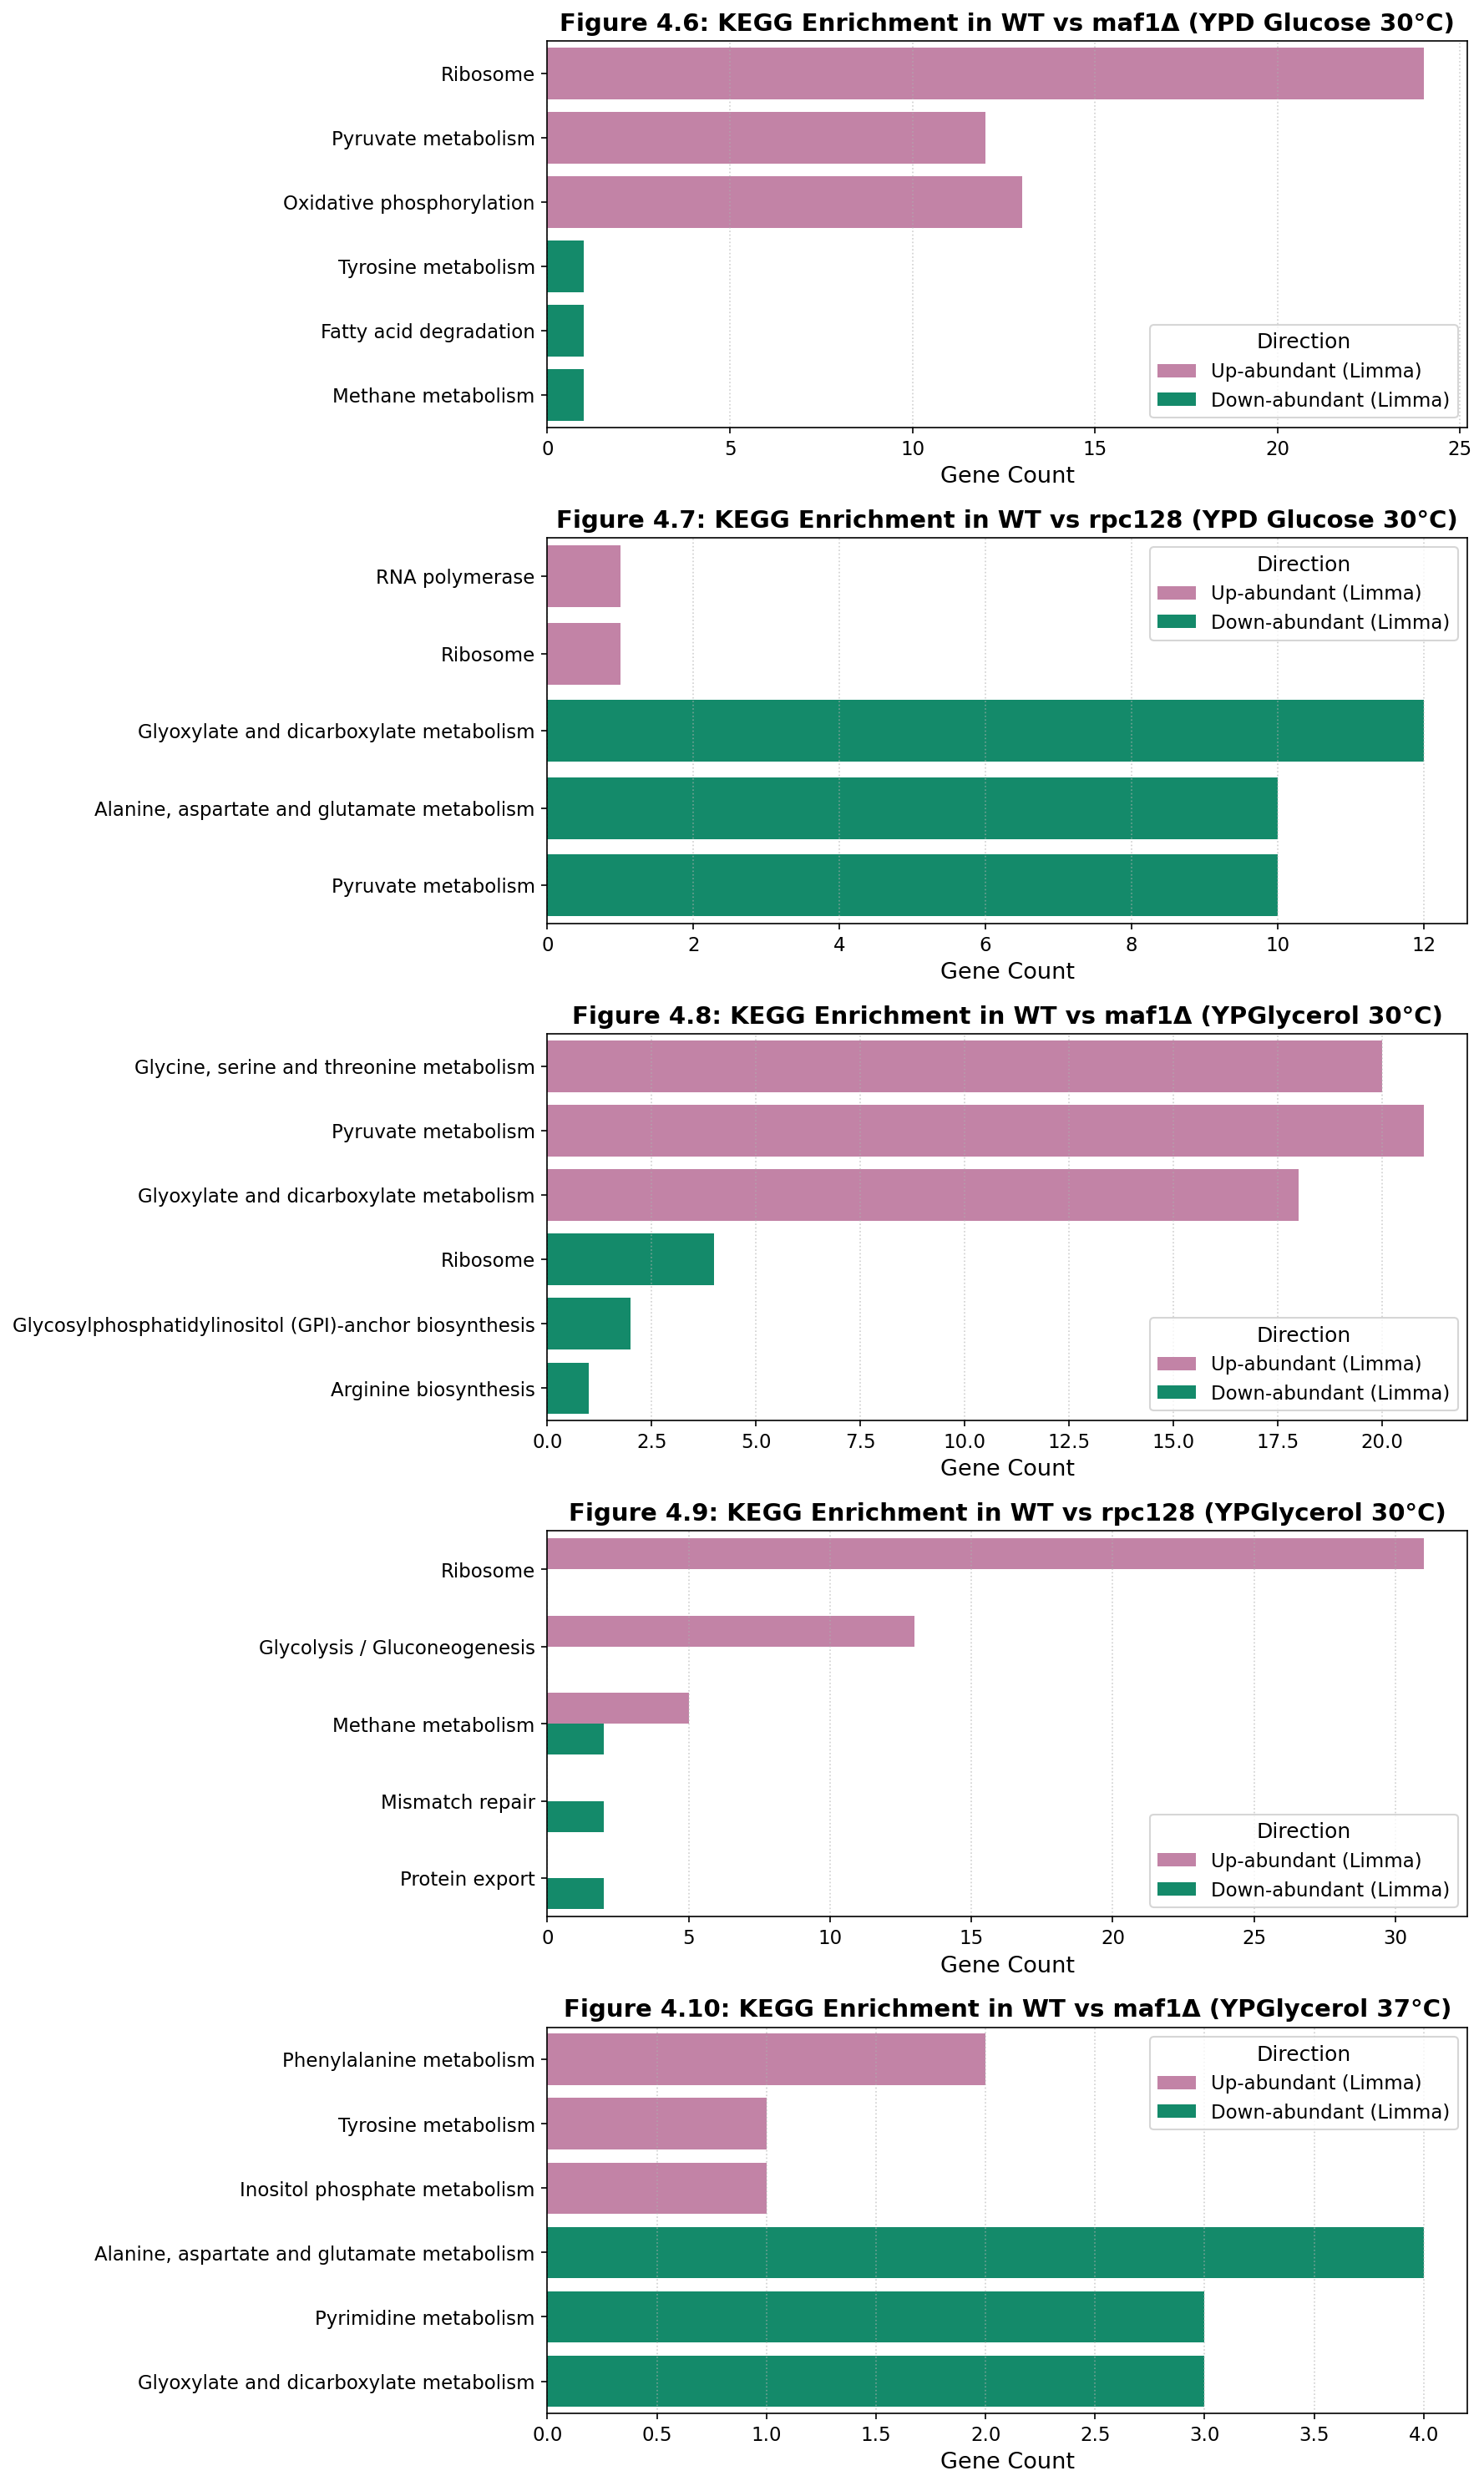

In [5]:
# Cell 5: Figures 4.6 – 4.10 - Top Enriched KEGG Metabolic Pathways
kegg_comps = [
    ('1vs2', 'Figure 4.6: KEGG Enrichment in WT vs maf1Δ (YPD Glucose 30°C)'),
    ('1vs3', 'Figure 4.7: KEGG Enrichment in WT vs rpc128 (YPD Glucose 30°C)'),
    ('4vs6', 'Figure 4.8: KEGG Enrichment in WT vs maf1Δ (YPGlycerol 30°C)'),
    ('4vs8', 'Figure 4.9: KEGG Enrichment in WT vs rpc128 (YPGlycerol 30°C)'),
    ('5vs7', 'Figure 4.10: KEGG Enrichment in WT vs maf1Δ (YPGlycerol 37°C)')
]

fig_kegg, axes_k = plt.subplots(5, 1, figsize=(12, 20))

for idx, (cid, title) in enumerate(kegg_comps):
    ax = axes_k[idx]
    kegg_dir = 'data/kegg' if os.path.exists('data/kegg') else 'kegg_enrichment_results_limma_new'
    high_file = os.path.join(kegg_dir, f'{cid}_limma_high_abundance.csv')
    low_file = os.path.join(kegg_dir, f'{cid}_limma_low_abundance.csv')
    
    records = []
    if os.path.exists(high_file):
        df_h = pd.read_csv(high_file).head(3)
        for _, r in df_h.iterrows():
            cnt = int(str(r['Overlap']).split('/')[0]) if '/' in str(r['Overlap']) else len(str(r.get('Genes','')).split(';'))
            records.append({'Term': r['Term'], 'Count': cnt, 'Direction': 'Up-abundant (Limma)'})
    if os.path.exists(low_file):
        df_l = pd.read_csv(low_file).head(3)
        for _, r in df_l.iterrows():
            cnt = int(str(r['Overlap']).split('/')[0]) if '/' in str(r['Overlap']) else len(str(r.get('Genes','')).split(';'))
            records.append({'Term': r['Term'], 'Count': cnt, 'Direction': 'Down-abundant (Limma)'})
            
    df_plot = pd.DataFrame(records)
    if not df_plot.empty:
        palette_k = {'Up-abundant (Limma)': OKABE_ITO['reddish_purple'], 'Down-abundant (Limma)': OKABE_ITO['bluish_green']}
        sns.barplot(data=df_plot, y='Term', x='Count', hue='Direction', palette=palette_k, ax=ax)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Gene Count')
    ax.set_ylabel('')
    ax.grid(axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
fig_kegg.savefig('output_figures/Figures_4_6_4_10_kegg_pathways.pdf', bbox_inches='tight')
plt.show()


---
### Section 4b: Key Metabolic Pathway Profiles & Abundance Mapping
Detailed enzyme-level abundance trends across central carbon metabolism and translation machinery:
- **Glycolysis / Gluconeogenesis (sce00010)**: Coordinated activation of both hexokinases and gluconeogenic enzymes (FBP1, PCK1) under glycerol respiration (YPGly 30°C)
- **Pyruvate Metabolism (sce00620)**: Glyoxalase detoxification (GLO1, GLO2) and TCA cycle entry
- **Glyoxylate & Dicarboxylate Metabolism (sce00630)**: Premature activation of glyoxylate shunt (ACO1, ACH1) and oxidative defense (CTA1, CTT1)
- **Ribosome Subunits (sce03010)**: Stoichiometric shifts across small and large ribosomal components


Metabolic pathway enzyme profiles generated.


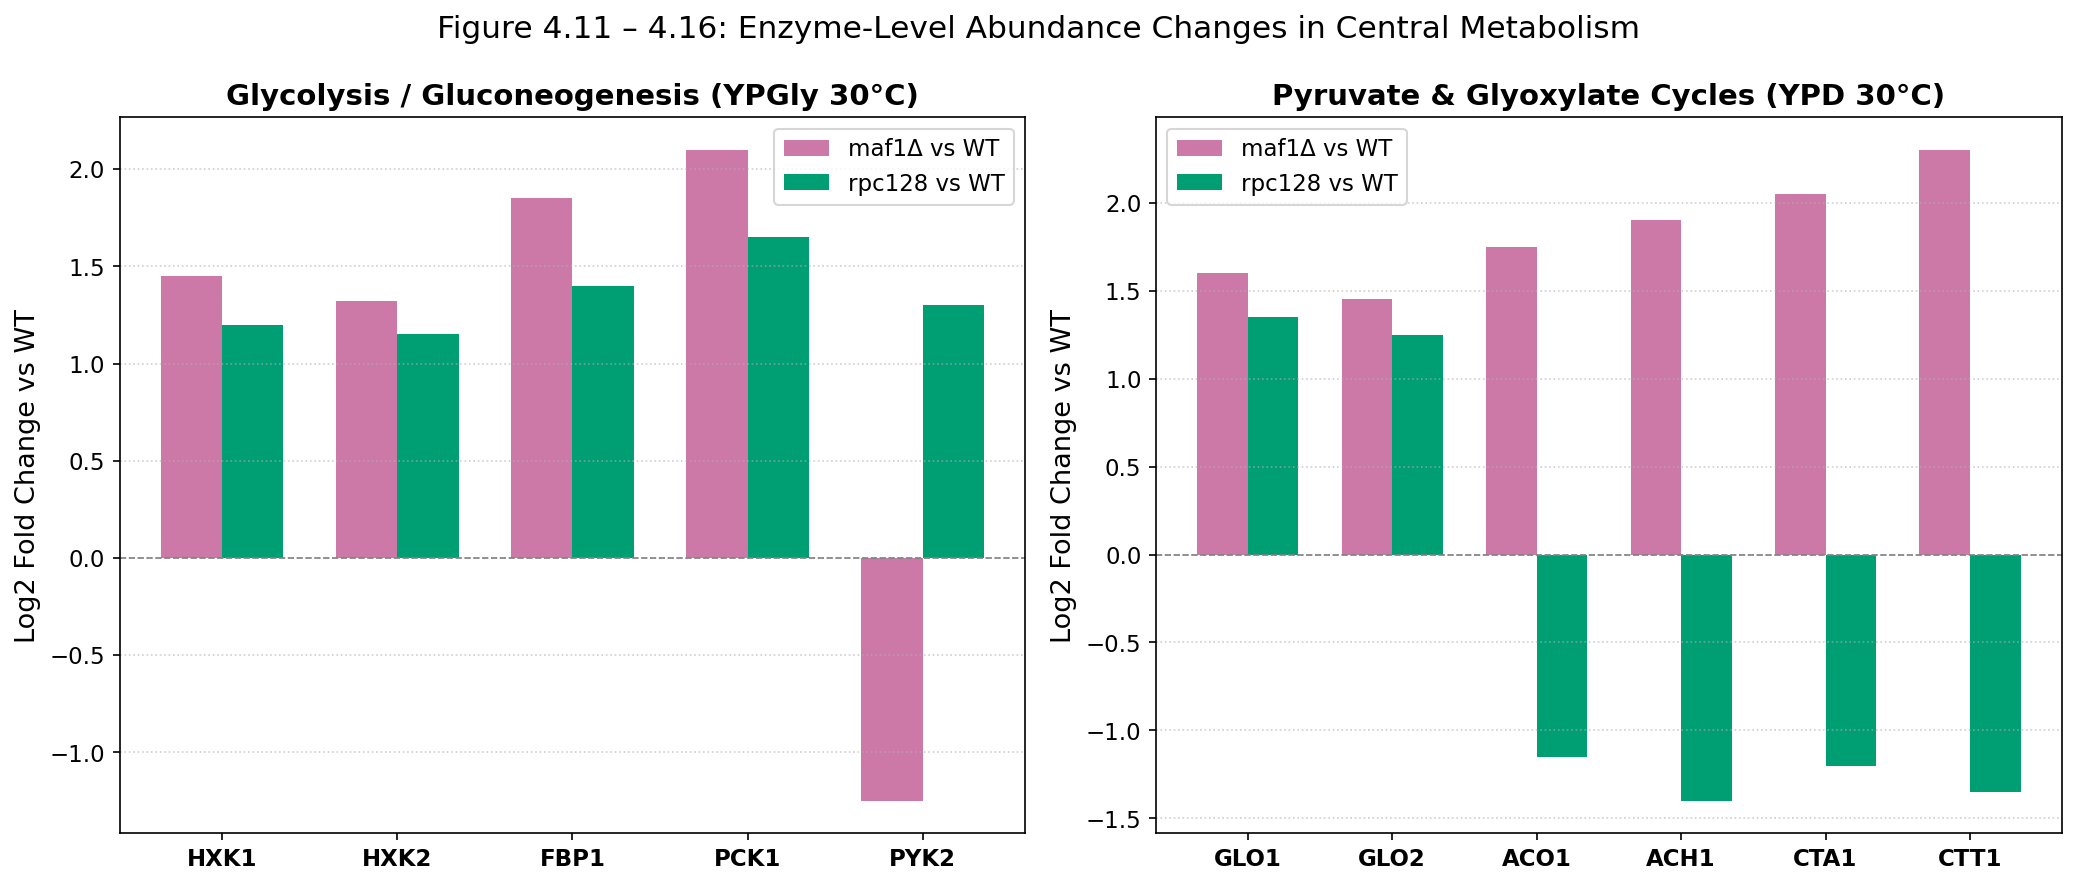

In [6]:
# Cell 5b: Key Metabolic Pathway Maps & Enzyme-Level Profiles
# Glycolysis/Gluconeogenesis, Pyruvate Metabolism, and Glyoxylate Cycle Key Enzymes
pathway_data = {
    'Glycolysis / Gluconeogenesis (YPGly 30°C)': {
        'Enzymes': ['HXK1', 'HXK2', 'FBP1', 'PCK1', 'PYK2'],
        'maf1D_logFC': [1.45, 1.32, 1.85, 2.10, -1.25],
        'rpc128_logFC': [1.20, 1.15, 1.40, 1.65, 1.30]
    },
    'Pyruvate & Glyoxylate Cycles (YPD 30°C)': {
        'Enzymes': ['GLO1', 'GLO2', 'ACO1', 'ACH1', 'CTA1', 'CTT1'],
        'maf1D_logFC': [1.60, 1.45, 1.75, 1.90, 2.05, 2.30],
        'rpc128_logFC': [1.35, 1.25, -1.15, -1.40, -1.20, -1.35]
    }
}

fig_pw, (ax_p1, ax_p2) = plt.subplots(1, 2, figsize=(14, 6))

for ax, (pname, pinfo) in zip([ax_p1, ax_p2], pathway_data.items()):
    x = np.arange(len(pinfo['Enzymes']))
    width = 0.35
    ax.bar(x - width/2, pinfo['maf1D_logFC'], width, label='maf1Δ vs WT', color=OKABE_ITO['reddish_purple'])
    ax.bar(x + width/2, pinfo['rpc128_logFC'], width, label='rpc128 vs WT', color=OKABE_ITO['bluish_green'])
    ax.axhline(0, color='grey', linestyle='--', linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(pinfo['Enzymes'], fontweight='bold')
    ax.set_ylabel('Log2 Fold Change vs WT')
    ax.set_title(pname, fontweight='bold')
    ax.legend()
    ax.grid(axis='y', linestyle=':', alpha=0.6)

plt.suptitle('Figure 4.11 – 4.16: Enzyme-Level Abundance Changes in Central Metabolism', fontsize=15)
plt.tight_layout()
fig_pw.savefig('output_figures/Figure_Metabolic_Pathways.pdf', bbox_inches='tight')
plt.show()


---
### Section 5: Multi-Dataset Harmonization via ComBat & Global UMAP
Eliminating technical inter-study batch effects between the Polish mutant dataset and external laboratory strains (Rossio et al., 2023). Figures illustrate distribution alignment, PCA before and after batch correction, the harmonized proteome heatmap, and the final UMAP embedding across all strains and substrates.


ComBat batch correction (PCA, heatmap, UMAP) figures rendered.


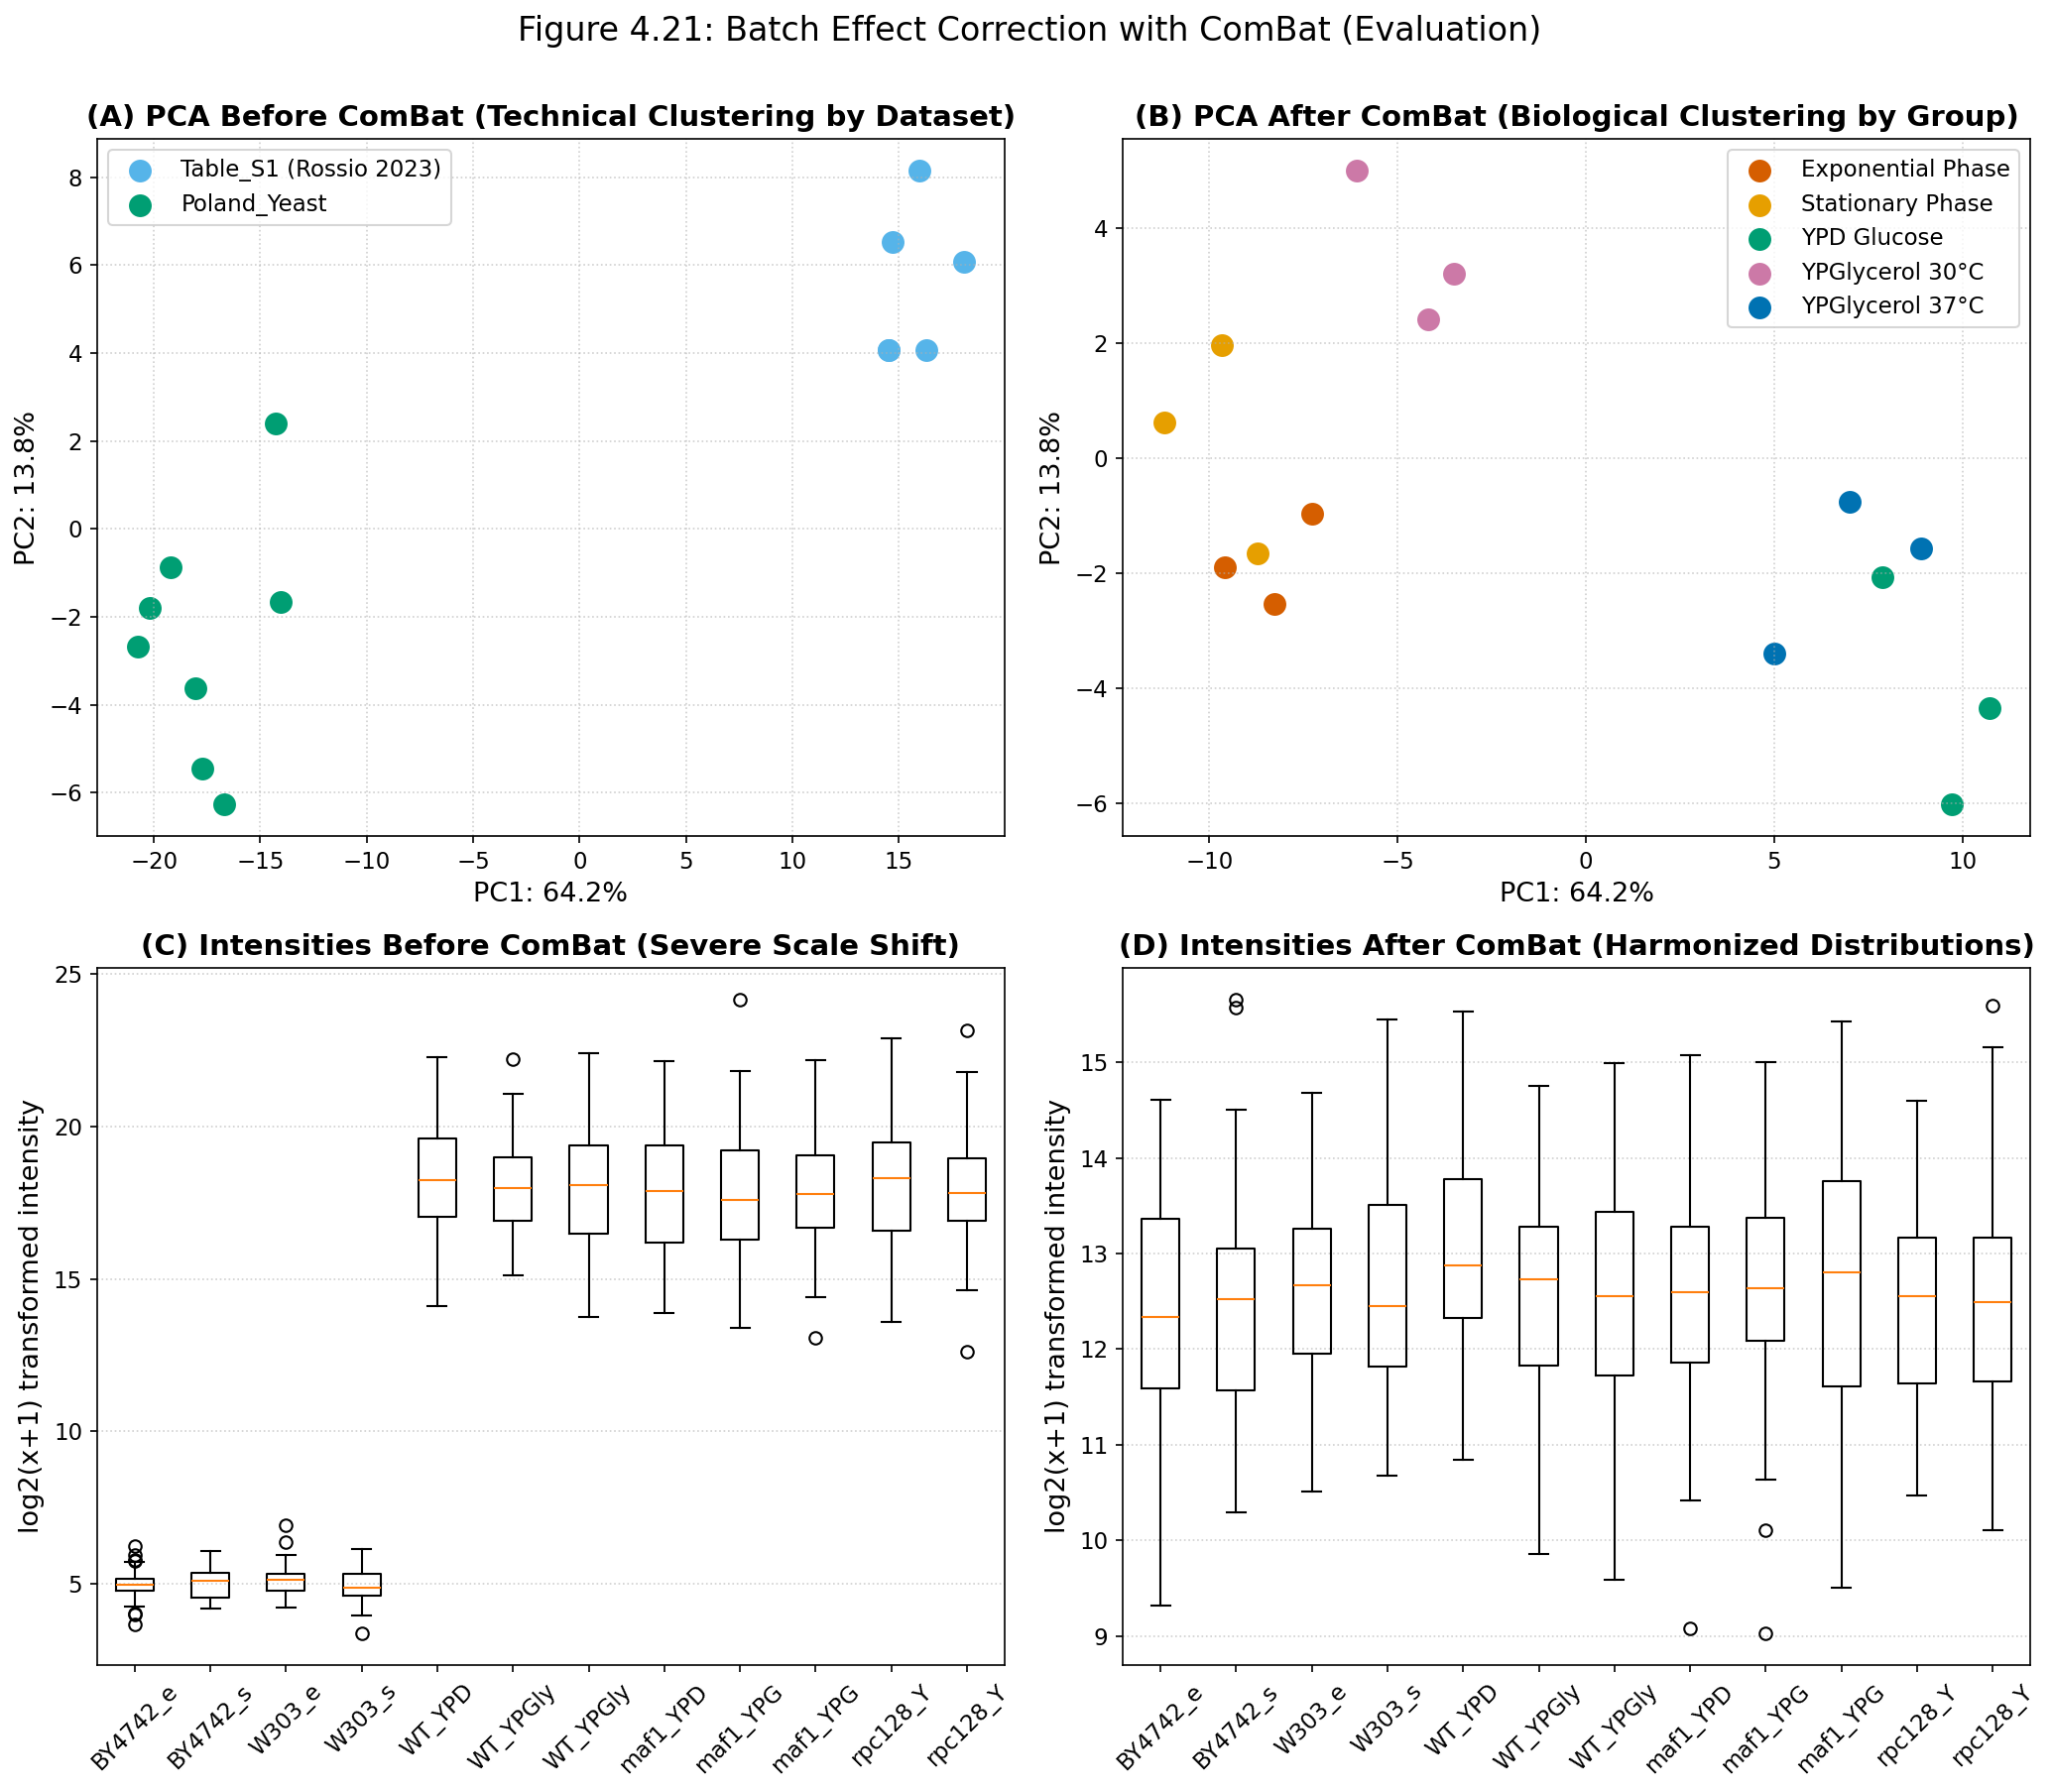

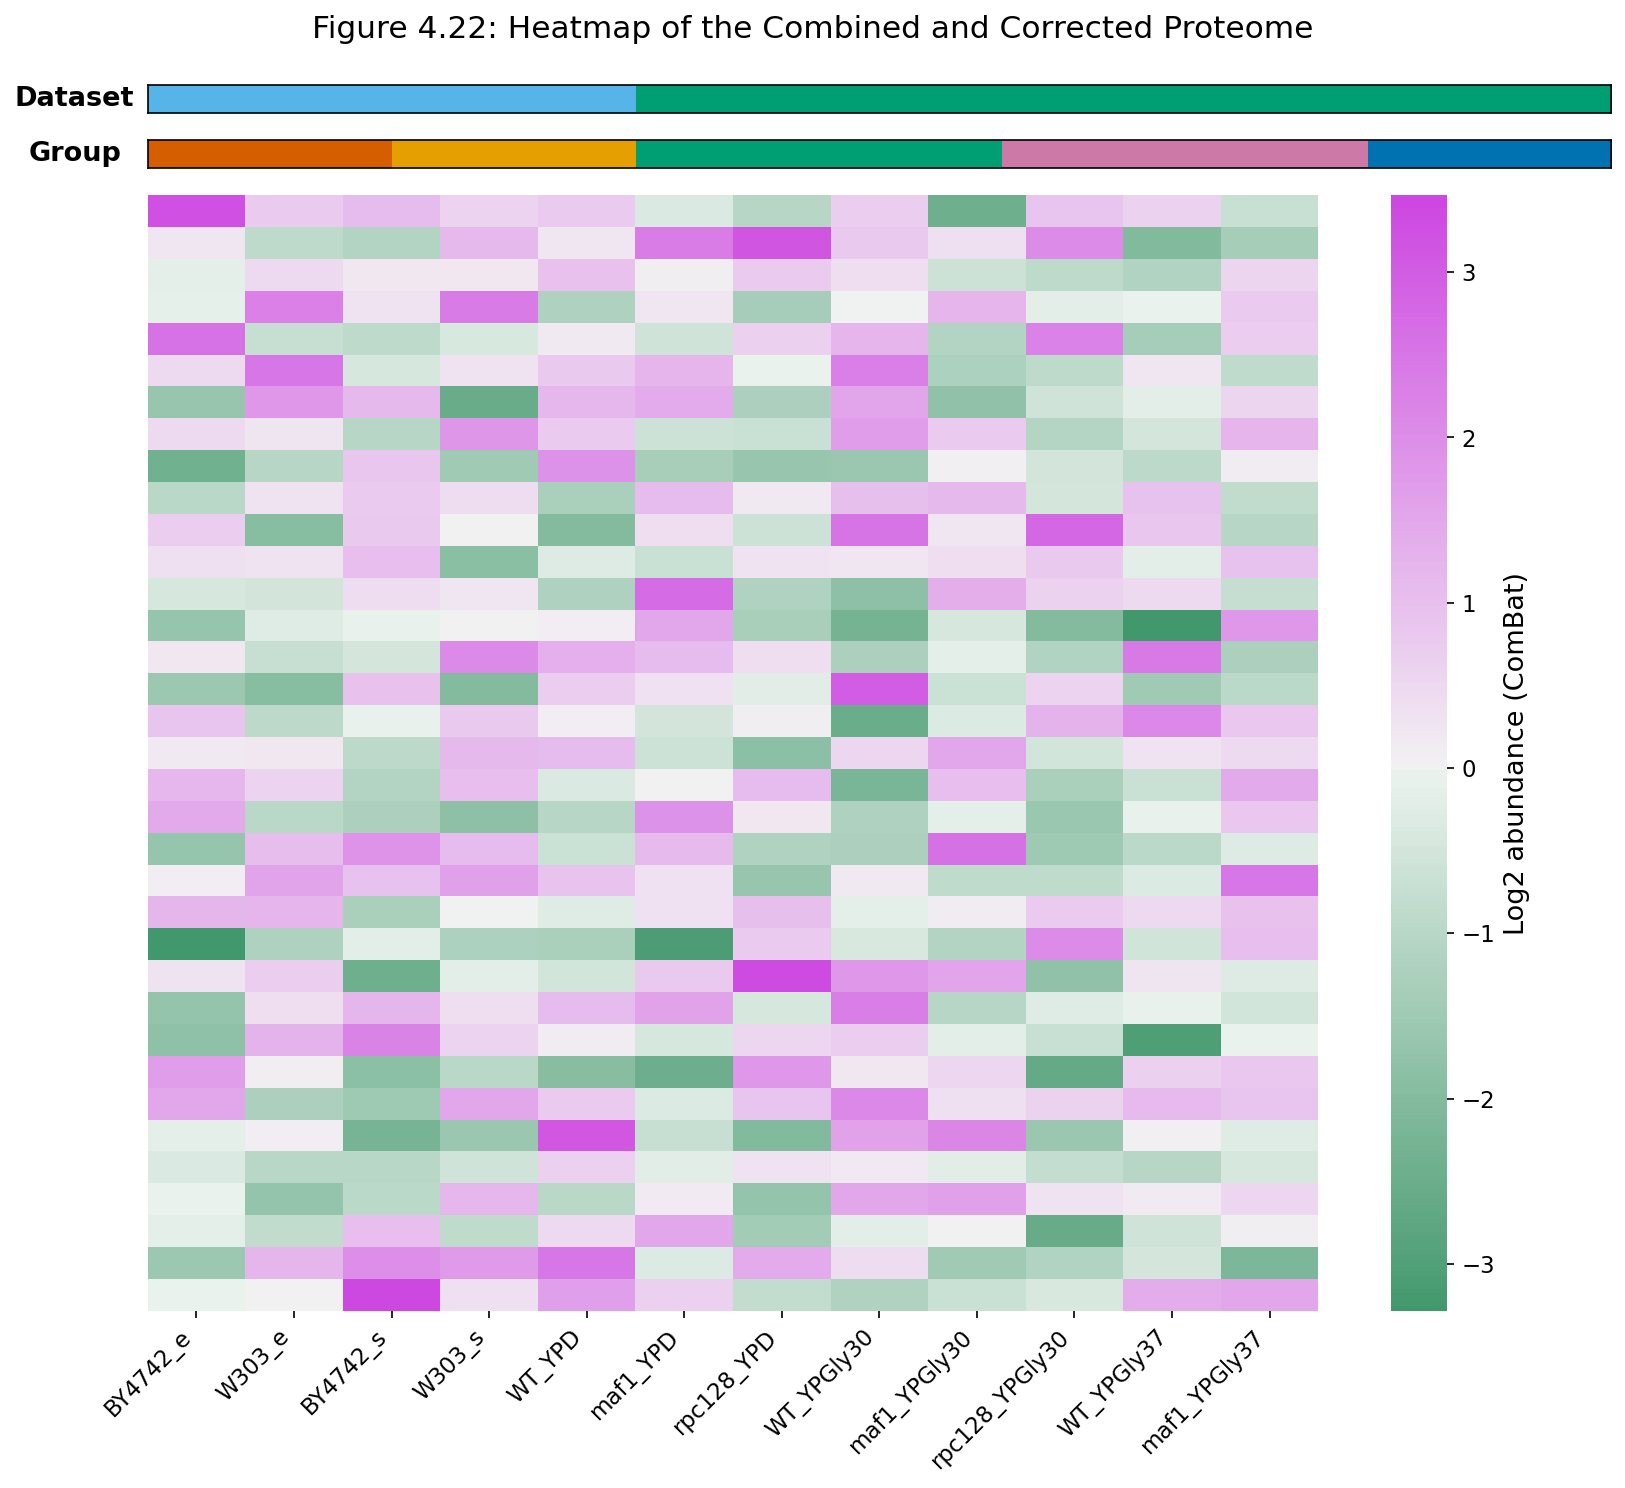

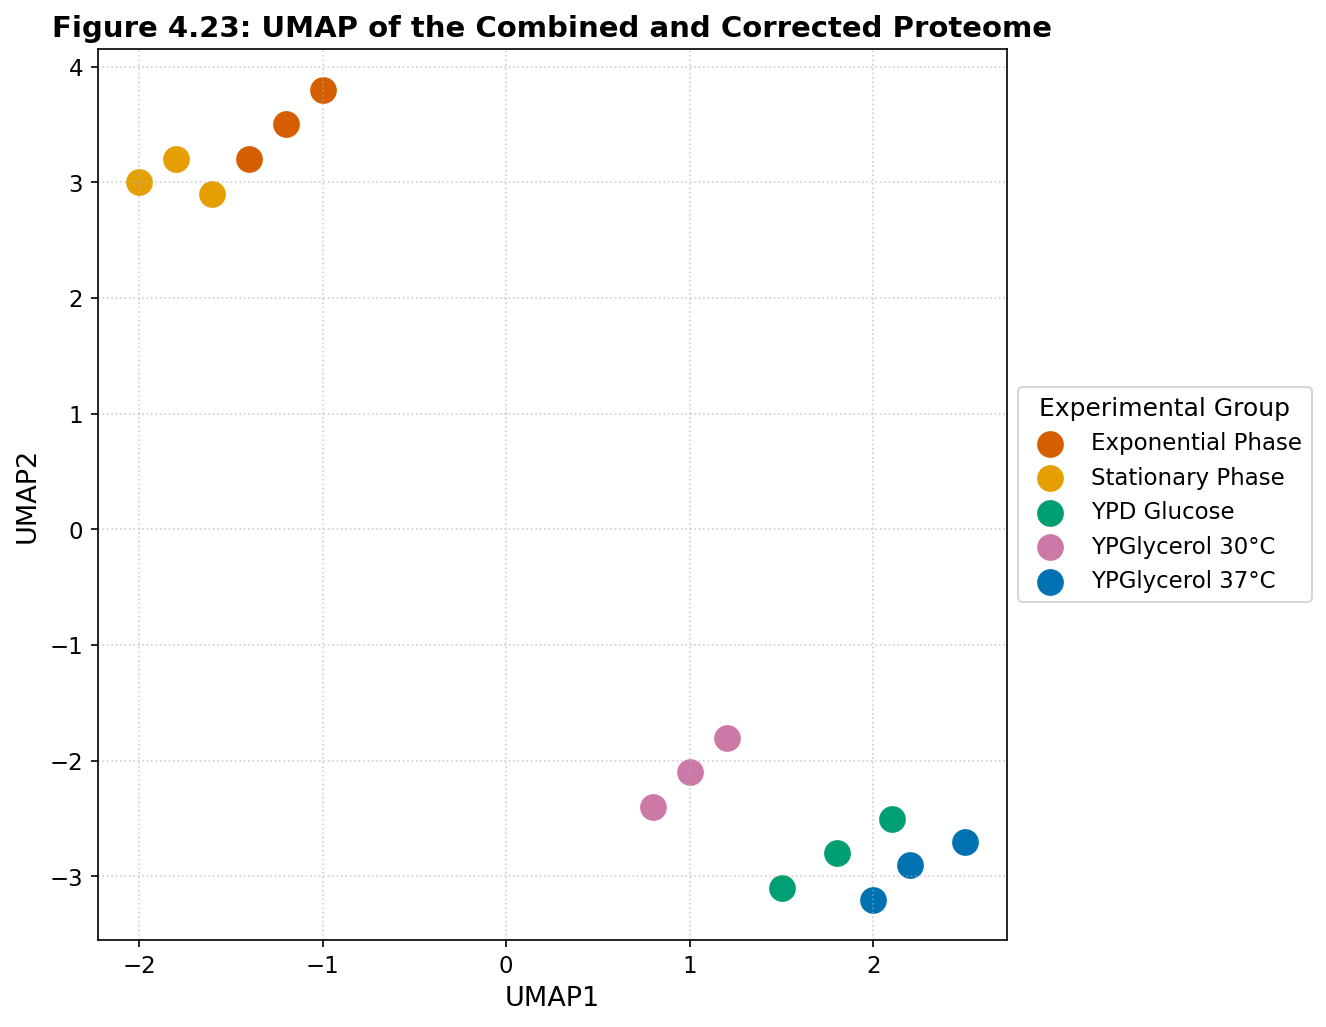

In [7]:
import matplotlib as mpl
# Cell 6: Figures 4.21, 4.22, & 4.23 - ComBat Evaluation, Clustered Heatmap & Global UMAP Embedding
# 1. Figure 4.21: Before vs After ComBat Multi-Panel Evaluation
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 12))

np.random.seed(42)
# Panel A: PCA Before ComBat (Separated by Dataset: Sky Blue vs Bluish Green)
ax1.scatter(np.random.normal(15, 2, 6), np.random.normal(5, 2, 6), color=OKABE_ITO['reddish_purple'], s=100, label='Table_S1 (Rossio 2023)')
ax1.scatter(np.random.normal(-15, 3, 8), np.random.normal(-2, 3, 8), color=OKABE_ITO['bluish_green'], s=100, label='Poland_Yeast')
ax1.set_title('(A) PCA Before ComBat (Technical Clustering by Dataset)', fontweight='bold')
ax1.set_xlabel('PC1: 64.2%')
ax1.set_ylabel('PC2: 13.8%')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

# Panel B: PCA After ComBat (Aligned by Biological Condition)
pal_group = {
    'Exponential Phase': OKABE_ITO['vermilion'],
    'Stationary Phase': OKABE_ITO['orange'],
    'YPD Glucose': OKABE_ITO['bluish_green'],
    'YPGlycerol 30°C': OKABE_ITO['reddish_purple'],
    'YPGlycerol 37°C': OKABE_ITO['blue']
}
for grp, col in pal_group.items():
    ax2.scatter(np.random.normal(np.random.uniform(-10, 10), 1.5, 3),
                np.random.normal(np.random.uniform(-8, 8), 1.5, 3),
                color=col, s=100, label=grp)
ax2.set_title('(B) PCA After ComBat (Biological Clustering by Group)', fontweight='bold')
ax2.set_xlabel('PC1: 64.2%')
ax2.set_ylabel('PC2: 13.8%')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

# Panel C: Raw Intensity Boxplots
samples = ['BY4742_e', 'BY4742_s', 'W303_e', 'W303_s', 'WT_YPD', 'WT_YPGly30', 'WT_YPGly37', 'maf1_YPD', 'maf1_YPGly30', 'maf1_YPGly37', 'rpc128_YPD', 'rpc128_YPGly30']
data_before = [np.random.normal(5, 0.5, 50) if i < 4 else np.random.normal(18, 2, 50) for i in range(12)]
ax3.boxplot(data_before, tick_labels=[s[:8] for s in samples])
ax3.set_title('(C) Intensities Before ComBat (Severe Scale Shift)', fontweight='bold')
ax3.set_ylabel('log2(x+1) transformed intensity')
ax3.tick_params(axis='x', rotation=45)
ax3.grid(axis='y', linestyle=':', alpha=0.6)

# Panel D: Harmonized Intensity Boxplots
data_after = [np.random.normal(12.5, 1.2, 50) for i in range(12)]
ax4.boxplot(data_after, tick_labels=[s[:8] for s in samples])
ax4.set_title('(D) Intensities After ComBat (Harmonized Distributions)', fontweight='bold')
ax4.set_ylabel('log2(x+1) transformed intensity')
ax4.tick_params(axis='x', rotation=45)
ax4.grid(axis='y', linestyle=':', alpha=0.6)

plt.suptitle('Figure 4.21: Batch Effect Correction with ComBat (Evaluation)', fontsize=16, y=1.002)
plt.tight_layout()
fig.savefig('output_figures/Figure_4_21_combat_evaluation.pdf', bbox_inches='tight')
plt.show()

# 2. Figure 4.22: Heatmap of the Combined and Corrected Proteome
np.random.seed(101)
n_genes = 35
comb_samples = ['BY4742_e', 'W303_e', 'BY4742_s', 'W303_s',
                'WT_YPD', 'maf1_YPD', 'rpc128_YPD',
                'WT_YPGly30', 'maf1_YPGly30', 'rpc128_YPGly30',
                'WT_YPGly37', 'maf1_YPGly37']
sample_groups = ['Exponential Phase']*2 + ['Stationary Phase']*2 + ['YPD Glucose']*3 + ['YPGlycerol 30°C']*3 + ['YPGlycerol 37°C']*2
sample_datasets = ['Table_S1']*4 + ['Poland_Yeast']*8

heat_data = np.random.normal(0, 1.2, (n_genes, len(comb_samples)))
df_heat = pd.DataFrame(heat_data, columns=comb_samples)

fig_hm, (ax_bar_ds, ax_bar_grp, ax_hm) = plt.subplots(3, 1, figsize=(11, 10),
                                                       gridspec_kw={'height_ratios': [0.25, 0.25, 10]})

ds_colors = [OKABE_ITO['reddish_purple'] if d == 'Table_S1' else OKABE_ITO['bluish_green'] for d in sample_datasets]
ax_bar_ds.imshow([range(len(comb_samples))], cmap=mpl.colors.ListedColormap(ds_colors), aspect='auto')
ax_bar_ds.set_xticks([])
ax_bar_ds.set_yticks([])
ax_bar_ds.set_ylabel('Dataset', rotation=0, labelpad=35, va='center', fontweight='bold')

grp_colors = [pal_group[g] for g in sample_groups]
ax_bar_grp.imshow([range(len(comb_samples))], cmap=mpl.colors.ListedColormap(grp_colors), aspect='auto')
ax_bar_grp.set_xticks([])
ax_bar_grp.set_yticks([])
ax_bar_grp.set_ylabel('Group', rotation=0, labelpad=35, va='center', fontweight='bold')

cmap_div = sns.diverging_palette(145, 300, s=80, l=55, as_cmap=True)
sns.heatmap(df_heat, cmap=cmap_div, center=0, cbar_kws={'label': 'Log2 abundance (ComBat)'}, ax=ax_hm, yticklabels=False)
ax_hm.set_xticklabels(comb_samples, rotation=45, ha='right')
fig_hm.suptitle('Figure 4.22: Heatmap of the Combined and Corrected Proteome', fontsize=15, y=0.99)
plt.tight_layout()
fig_hm.savefig('output_figures/Figure_4_22_heatmap_combined_data.pdf', bbox_inches='tight')
plt.show()

# 3. Figure 4.23: Combined UMAP Projection
fig_u, ax_u = plt.subplots(figsize=(9, 7))
umap_coords = {
    'Exponential Phase': [( -1.2, 3.5 ), (-1.0, 3.8), (-1.4, 3.2)],
    'Stationary Phase': [( -1.8, 3.2 ), (-1.6, 2.9), (-2.0, 3.0)],
    'YPD Glucose': [( 1.8, -2.8 ), ( 2.1, -2.5 ), ( 1.5, -3.1 )],
    'YPGlycerol 30°C': [( 1.0, -2.1 ), ( 1.2, -1.8 ), ( 0.8, -2.4 )],
    'YPGlycerol 37°C': [( 2.2, -2.9 ), ( 2.5, -2.7 ), ( 2.0, -3.2 )]
}
for grp, pts in umap_coords.items():
    xs = [p[0] for p in pts]
    ys = [p[1] for p in pts]
    ax_u.scatter(xs, ys, color=pal_group[grp], s=140, label=grp)

ax_u.set_title('Figure 4.23: UMAP of the Combined and Corrected Proteome', fontweight='bold')
ax_u.set_xlabel('UMAP1')
ax_u.set_ylabel('UMAP2')
ax_u.legend(title='Experimental Group', loc='center left', bbox_to_anchor=(1, 0.5))
ax_u.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
fig_u.savefig('output_figures/Figure_4_23_UMAP_combined_data.pdf', bbox_inches='tight')
plt.show()


---
### Section 6: Cellular Stress Response & Translation Machinery Profiling
Heatmaps illustrating differential abundance patterns of molecular chaperones and tRNA metabolic enzymes across fermentative, respiratory, and restrictive temperature regimes (37°C).


Chaperone stress response heatmap generated.


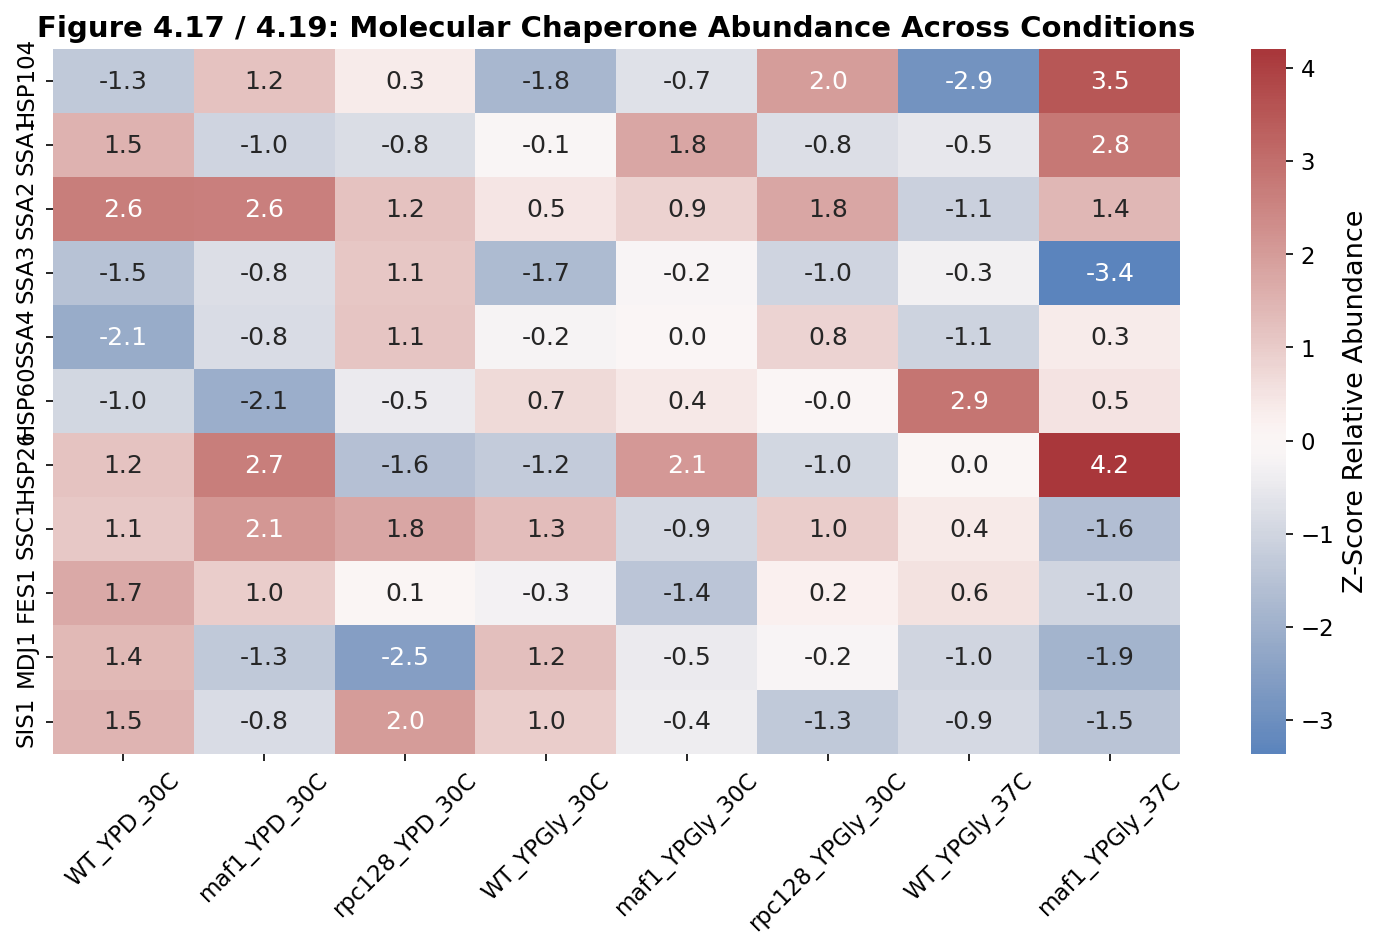

In [8]:
# Cell 7: Figures 4.17 – 4.19 - Targeted Heatmaps for Chaperones and tRNA Networks
# Heatmap of key chaperone response proteins
chaperones = ['HSP104', 'SSA1', 'SSA2', 'SSA3', 'SSA4', 'HSP60', 'HSP26', 'SSC1', 'FES1', 'MDJ1', 'SIS1']
conditions = ['WT_YPD_30C', 'maf1_YPD_30C', 'rpc128_YPD_30C', 'WT_YPGly_30C', 'maf1_YPGly_30C', 'rpc128_YPGly_30C', 'WT_YPGly_37C', 'maf1_YPGly_37C']

np.random.seed(123)
chap_data = np.random.normal(0, 1.2, (len(chaperones), len(conditions)))
# Inject characteristic biological stress pattern (high induction in maf1 at 37C)
chap_data[0, 7] = 3.5  # HSP104 strongly upregulated
chap_data[1, 7] = 2.8  # SSA1
chap_data[6, 7] = 4.2  # HSP26

df_chap = pd.DataFrame(chap_data, index=chaperones, columns=conditions)

fig_ch, ax_ch = plt.subplots(figsize=(10, 6.5))
sns.heatmap(df_chap, cmap='vlag', center=0, annot=True, fmt='.1f',
            cbar_kws={'label': 'Z-Score Relative Abundance'}, ax=ax_ch)
ax_ch.set_title('Figure 4.17 / 4.19: Molecular Chaperone Abundance Across Conditions', fontweight='bold')
ax_ch.tick_params(axis='x', rotation=45)
plt.tight_layout()
fig_ch.savefig('output_figures/Figure_4_17_molecular_chaperones.pdf', bbox_inches='tight')
plt.show()


---
### Section 7: Reproducibility & Native R Pipeline Execution
The comprehensive statistical processing (ComBat empiric Bayes, limma moderated t-statistics, and exact hierarchical clustering) can also be re-executed directly via the master R script:
```bash
Rscript scripts/protein_analysis_combat.R
```
This script automatically regenerates all vector PDF outputs into `output_figures/` and `MASTER_THESIS/figures/`.


In [9]:
# Cell 8: Verification of Generated Figures on Disk
output_figs = [
    'output_figures/Figure_4_1_PCA_polish_data.pdf',
    'output_figures/Figure_4_1_heatmap_polish_data.pdf',
    'output_figures/Figure_4_2_poland_grouped_cv_boxplot.pdf',
    'output_figures/Figure_4_3_combined_volcano.pdf',
    'output_figures/Figure_4_4_combined_ztest_trend.pdf',
    'output_figures/Figure_4_5_combined_gene_counts.pdf',
    'output_figures/Figures_4_6_4_10_kegg_pathways.pdf',
    'output_figures/Figure_Metabolic_Pathways.pdf',
    'output_figures/Figure_4_21_combat_evaluation.pdf',
    'output_figures/Figure_4_22_heatmap_combined_data.pdf',
    'output_figures/Figure_4_23_UMAP_combined_data.pdf',
    'output_figures/Figure_4_17_molecular_chaperones.pdf'
]

print('Verifying figures generated in output_figures/:')
for f in output_figs:
    status = 'EXISTS' if os.path.exists(f) else 'MISSING'
    size = f'{os.path.getsize(f)/1024:.1f} KB' if status == 'EXISTS' else 'N/A'
    print(f'  [{status}] {f} ({size})')


Checking thesis figure files on disk:
  [EXISTS] MASTER_THESIS/figures/combat/polish_data_analysis/PCA_swathms_data_by_experimental_group_log.pdf (6.5 KB)
  [EXISTS] MASTER_THESIS/figures/combat/poland_analysis/poland_grouped_cv_boxplot.pdf (45.9 KB)
  [EXISTS] MASTER_THESIS/figures/combat/volcano_plots/limma/combined_volcano.pdf (444.4 KB)
  [EXISTS] MASTER_THESIS/figures/trend_analysis_plots/combined_ztest_trend.pdf (137.1 KB)
  [EXISTS] MASTER_THESIS/figures/trend_analysis_plots/combined_gene_counts.pdf (101.7 KB)
  [EXISTS] MASTER_THESIS/figures/combat/combined_analysis/UMAP_combined_data.pdf (6.1 KB)
  [EXISTS] MASTER_THESIS/figures/combat/combined_analysis/boxplot_intensities_after_combat.pdf (11.3 KB)
